# CIFAR-10 ResNet under 5M parameters: Scheme B, Wide ResNet WRN-16/22/28

**Current launch: T72 (H.W.; selected, not trained).** B ver-1 control, 200 epochs with five-epoch warmup and LR drops ×0.2 after epochs60/120/160; Cutout16, smoothing0.1, EMA; fresh training. Versions allocate automatically; no parent checkpoint is loaded.

NYU Tandon Deep Learning (Fall 2026), Project 1 ([Kaggle competition](https://www.kaggle.com/competitions/cifar-10-res-net-architecture-challenge-dl)).
A residual network is trained **from scratch** on the 50,000 provided CIFAR-10 training images and predicts the
2,000 hidden test images. No pretrained weights and no external data are used.

| | |
|---|---|
| Original baseline architecture | WRN-22-4: 3×3 stem (16 channels) → 3 groups of 3 pre-activation blocks (BN-ReLU-conv-BN-ReLU-conv) with widths 64/128/256, strides 1/2/2, 1×1 conv shortcuts where the shape changes → BN-ReLU → global average pool → linear |
| Original baseline parameters | **4,298,970** (budget 5,000,000) |
| Original R0 training | 200 epochs, SGD with Nesterov momentum 0.9, lr 0.1, batch 128, weight decay 5e-4, 5-epoch linear warmup + cosine decay, label smoothing 0.1, random crop + flip + Cutout 16×16, EMA of the weights (decay 0.999) |
| Other schemes | `A_resnet.ipynb` (BasicBlock ResNet), `C_seresnet.ipynb` (SE-ResNet), `E_pyramid.ipynb` (PyramidNet-110), `F_shake.ipynb` (Shake-Shake-26 2×40d) and `G_resnext.ipynb` (ResNeXt-29 32×4d). Architecture and launch settings differ; C also has the T31 padding switch in its data, resume and export helpers. |

**Usage.** Edit the configuration cell (section 1), then *Run all*. The notebook detects whether it runs locally,
on Google Colab or on Kaggle (section 2). Use `RESUME_RUN` to continue a previous experiment explicitly.
See `README.md` for details.

**Sections.** 1 Configuration · 2 Environment · 3 Data · 4 Model · 5 Training · 6 Training curves ·
7 Prediction and submission · 8 Final results

**Main references.** Zagoruyko & Komodakis, *Wide Residual Networks*, BMVC 2016, and their
[reference code](https://github.com/szagoruyko/wide-residual-networks); He et al., *Identity Mappings in Deep
Residual Networks*, ECCV 2016; DeVries & Taylor, *Cutout*, 2017. The full list is in `README.md`.

**Run on Colab A100:** approve Drive access and run all cells. Keep `RESUME_RUN=None`, `MODEL_VERSION=None`, `RUN_NAME="step200-ema"`. For interrupted-run resume, use its exact ID, `RUN_NAME=None` and unchanged scientific settings.

**Evaluation:** compare final200/EMA/flip with the corresponding original baseline. Best/final × raw/EMA × plain/flip remain exported; the best/auto/flip submission choice is recorded separately. Data/cache reuse and best/last checkpoints on Drive remain automatic.

Previous launch notebooks and execution outputs are preserved in `result/configs/11-01-13-02_project1-ver-51-t71t72-launch_before-launch.zip`. This launch copy clears stale outputs.


## 1. Configuration

**Current launch: T72 (H.W.; selected, not trained).** B ver-1 control, 200 epochs with five-epoch warmup and LR drops ×0.2 after epochs60/120/160; Cutout16, smoothing0.1, EMA; fresh training. Versions allocate automatically; no parent checkpoint is loaded.

Edit this cell, then Run all. Every new experiment receives a New York timestamp and a separate artifact tree.
Set `RESUME_RUN` to the exact previous run ID to resume; changing a training setting during resume is rejected.
Leave `RUN_NAME=None` when resuming. There is no destructive overwrite option.

Use `VAL_SIZE=5000` for comparisons. After selecting a recipe, use `VAL_SIZE=0`, `TRAIN_SUBSET=0`,
and explicitly set `WEIGHTS="model"` or `"ema"` from the validation experiments for the final refit.
A two-epoch smoke test also needs `WARMUP_EPOCHS=0` or `1` and `TRAIN_SUBSET >= BATCH_SIZE`.

Names now use `MM-DD-HH-mm_<notebook-stem>-ver-<version>-<TXX>-<features>_<role>.<extension>` in `America/New_York`. The full year and timezone remain in metadata. Notebook stems are `A_resnet`, `B_wrn`, `C_seresnet`, `E_pyramid`, `F_shake` and `G_resnext`; feature labels contain one or two words, defaulting to the augmentation and `ema` when enabled. `TASK_ID` records the checklist task (`T00` for original baselines). `MODEL_VERSION=None` chooses the next sequential version for that notebook in this result root. An explicit positive version is allowed only if unused. `RUN_NAME` optionally overrides the feature words (for example `cutout-ema`); it is no longer an arbitrary long label. Resume uses the exact existing `RESUME_RUN` and does not create a version.

For example, the first completed A run is `10-30-08-40_A_resnet-ver-1-T00-cutout-ema`. Its best checkpoint is `checkpoints/10-30-08-40_A_resnet-ver-1-T00-cutout-ema/10-30-08-40_A_resnet-ver-1-T00-cutout-ema_best-ckpt.pt`. Training artifacts use the run-start timestamp. Evaluations and exports use their creation minute and retain the same model/version/features; repeated outputs within a minute get a role suffix such as `submission-2.csv`. Dataset files and caches keep their existing names. Shared project checks/reviews use `project1-ver-<index>-<features>` because they are not attributable to one notebook. Directory-index `README.md` files retain their conventional name.

**Optional Mixup recipe (not active):** use `MIXUP=True`, alpha0.2/probability0.5, `AUG="basic"`, smoothing0 and an unused version. T49/T50/T51 are already completed; their A3/B3/C4 identities must not be reused. Keep Mixup off for T72. Resume must match the saved scientific settings.




In [20]:
# Scheme B: T72, fresh 200-epoch training; no checkpoint resume.
# Edit the values below, then Run all.

RUN_NAME = 'step200-ema'  # set None when resuming this interrupted trial
RESUME_RUN = None
EPOCHS = 200
AUG = 'cutout'
SEED = 0
VAL_SIZE = 5000
EMA = True
AMP = "auto"             # CUDA only: "auto" = bf16 on GPUs with native bf16 (e.g. A100), else fp16 | "off" | "bf16" | "fp16"
CKPT_EVERY = None        # write last-ckpt.pt every N epochs; None = 5 on Colab (Drive writes are slow), else 1
TRAIN_SUBSET = 0
# New runs never overwrite previous outputs. Set RESUME_RUN explicitly to continue a run.

# Optimization
BATCH_SIZE = 128
LR = 0.1
MOMENTUM = 0.9
NESTEROV = True
WEIGHT_DECAY = 0.0005
WD_SKIP_BN_BIAS = False  # restore B ver-1 decay on BN/bias
WARMUP_EPOCHS = 5  # retained baseline warmup; adapted published schedule, not exact reproduction
LR_SCHEDULE = "multistep"  # cosine restores original B schedule
LR_MILESTONES = [60, 120, 160]  # drop after these completed epochs
LR_GAMMA = 0.2
LABEL_SMOOTHING = 0.1  # retain B ver-1
EMA_DECAY = 0.999

# Data and augmentation
SPLIT_SEED = 0
CUTOUT_SIZE = 16
AUTOAUG_ERASE = 'cutout'
ERASING_P = 0.5          # RandomErasing probability

# Training-only Mixup option (P13): requires AUG="basic" and smoothing 0 when enabled.
MIXUP = False  # off; retain hard-label Cutout recipe
MIXUP_ALPHA = 0.2        # positive Beta distribution parameter; one lambda per triggered batch
MIXUP_PROB = 0.5         # probability of mixing a training batch; validation/test never mix

# Hardware (None = automatic: on for CUDA, off for MPS / CPU)
DEVICE = None            # "cuda" | "mps" | "cpu"; None = $CIFAR_DEVICE, else cuda > mps > cpu
CHANNELS_LAST = None
CUDNN_BENCHMARK = None
PIN_MEMORY = None
WORKERS = None           # DataLoader workers for AUG = "autoaug" (always 0 on macOS / Windows, see section 2)
EVAL_BATCH_SIZE = 1000
LOG_INTERVAL = 0         # also print every N steps within an epoch (0 = off)
# Optional speed switches (README "Compilation"); neither is part of the recipe or of any fingerprint.
COMPILE = "off"          # torch.compile on CUDA: "off" | "default" | "reduce-overhead" | "max-autotune" | "max-autotune-no-cudagraphs"
BENCHMARK_STEPS = 0      # > 0: only time this many training steps (real data, current COMPILE); no run folder; then stop

# Prediction
CHECKPOINT = "best"      # checkpoint used for the submission: "best" (highest validation accuracy) | "last"
WEIGHTS = "auto"         # choose on validation using TTA; for VAL_SIZE=0 set "model" or "ema" explicitly
TTA = True               # average the softmax of each test image and its horizontal flip

# Runtime host, independent of the editor: auto | colab | kaggle | local.
# For a VS Code kernel connected to Colab, set "colab" if auto detection is ambiguous.
RUNTIME_ENV = "auto"     # explicit value overrides CIFAR_ENV; auto uses CIFAR_ENV then detection

# Paths (None = $CIFAR_DATA_DIR / $CIFAR_CACHE_DIR / $CIFAR_RESULT_DIR, else the default of the environment)
AUTO_DOWNLOAD = False     # Kaggle download/login code is commented out; use uploaded data
SAVE_CACHE_TO_DRIVE = True # on Colab, automatically save/verify MyDrive/DL_Project1/cache.zip
DATA_DIR = None          # Colab: MyDrive/DL_Project1/data/ (folder or override with a ZIP path)
CACHE_DIR = None
RESULT_DIR = None
SHOW_SUMMARY = True      # torchinfo layer table in section 4 (skipped if torchinfo is not installed)

# Architecture switches: choose one independent trial; preserve the original options for controls.
TASK_ID = 'T72'
MODEL_VERSION = None  # automatic sequential version; no advance reservation
WIDTH_PRESET = 'baseline'  # baseline; restore original WRN-22-4


## 2. Environment, paths and device

| Environment | Data | Cache | Results |
|---|---|---|---|
| Local | `project1/data` | `project1/cache` | `project1/result`, beside `Archive` |
| Colab | `MyDrive/DL_Project1/data` (manual upload), or explicit `DATA_DIR` | `/content/cache` | `MyDrive/DL_Project1/result` |
| Kaggle | Competition directory under `/kaggle/input` | `/kaggle/working/cache` | `/kaggle/working/result` |

Set `DATA_DIR`, `CACHE_DIR`, `RESULT_DIR` explicitly when needed. Their `CIFAR_*_DIR` environment variables
are fallback overrides. On Colab select an A100 GPU. Automatic precision uses bf16 on an A100;
channels-last and cuDNN benchmarking are enabled. AutoAugment uses forked workers on Linux and zero workers
on macOS/Windows. Keep the same hardware settings across architecture comparisons.

Artifacts are grouped by type under `result`: `checkpoints`, `configs`, `logs`, `evaluations/validation`,
`evaluations/test`, `plots`, `progress`, `manifests`, and `exports`. Each uses the same timestamped run ID.
The local default assumes the kernel starts in `project1` or `project1/Archive`; otherwise set paths explicitly.

Detection follows the remote Python kernel, even when the editor is VS Code. Runtime markers take priority
over directory names. Set `RUNTIME_ENV="colab"` in section 1 to explicitly select Colab paths; this overrides
`CIFAR_ENV`. It does not connect or move a local kernel to Colab. Restart the kernel and rerun from section 1
after changing it. Check the printed environment, kernel executable, GPU and paths.


In [21]:
import copy
import csv
import hashlib
import importlib.util
import importlib.metadata
import io
import json
import math
import os
import platform
import random
import re
import shutil
import subprocess
import sys
import time
import tempfile
import zlib
import zipfile
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from datetime import datetime
from zoneinfo import ZoneInfo
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from matplotlib.ticker import MaxNLocator
from PIL import Image

ENVS = ("local", "colab", "kaggle")
KAGGLE_SLUG = "cifar-10-res-net-architecture-challenge-dl"
DRIVE_PROJECT_DIR = "/content/drive/MyDrive/DL_Project1"
WORK_DIRS = {"colab": "/content", "kaggle": "/kaggle/working"}
COLAB_CKPT_EVERY = 5  # Drive writes are slow; best-ckpt.pt and the final epoch are always saved
PROJECT_DIR = Path.cwd().resolve()
LOCAL_PROJECT_DIR = PROJECT_DIR.parent if PROJECT_DIR.name == "Archive" else PROJECT_DIR
# Start method for the AutoAugment DataLoader workers: "fork" lets them use the Dataset class defined in this
# notebook. Under "spawn" (macOS, Windows) they cannot import it, so the pipeline runs in the main process there.
MP_CONTEXT = "fork" if sys.platform.startswith("linux") else None

_warned = set()


def _getenv(name):
    value = os.environ.get(name, "").strip()
    return value or None


def warn_once(msg):
    if msg not in _warned:
        _warned.add(msg)
        print(f"Warning: {msg}", flush=True)


def _module_exists(name):
    try:
        return importlib.util.find_spec(name) is not None
    except (ImportError, ValueError):
        return False


def detect_env():
    """Detect the kernel host, independent of the notebook editor (browser or VS Code)."""
    configured = str(globals().get("RUNTIME_ENV") or "auto").strip().lower()
    if configured not in ("auto",) + ENVS:
        raise ValueError(f"RUNTIME_ENV={configured!r}; expected auto or one of {ENVS}")
    requested = configured if configured != "auto" else (_getenv("CIFAR_ENV") or "auto").lower()
    if requested not in ("auto",) + ENVS:
        raise ValueError(f"CIFAR_ENV={requested!r}; expected auto or one of {ENVS}")
    if requested != "auto":
        return requested
    # Runtime markers beat directory names: /kaggle/input may also exist on Colab.
    if any(_getenv(key) for key in ("COLAB_RELEASE_TAG", "COLAB_BACKEND_VERSION")):
        return "colab"
    if _getenv("KAGGLE_KERNEL_RUN_TYPE"):
        return "kaggle"
    if _module_exists("google.colab"):
        return "colab"
    # A directory alone is weak evidence; use the full layout only as a fallback.
    if os.path.isdir("/kaggle/input") and os.path.isdir("/kaggle/working"):
        return "kaggle"
    return "local"


def work_dir(env=None):
    env = env or detect_env()
    return Path(_getenv("CIFAR_WORK_DIR") or WORK_DIRS.get(env, PROJECT_DIR))


def drive_dir():
    return Path(_getenv("CIFAR_DRIVE_DIR") or DRIVE_PROJECT_DIR)


def drive_mounted():
    return drive_dir().parent.is_dir()  # .../MyDrive exists once Drive is mounted


def kaggle_input_dir():
    return Path(_getenv("CIFAR_KAGGLE_INPUT") or "/kaggle/input")


def find_competition_data(root=None, max_depth=6):
    """Directories under `root` that contain train_labels.csv, best match first.

    Breadth-first, follows symlinks, skips *_images folders (50k files) and hidden folders.
    """
    root = Path(root or kaggle_input_dir())
    found, frontier = [], [(root, 0)]
    while frontier:
        d, depth = frontier.pop(0)
        try:
            entries = sorted(os.scandir(d), key=lambda e: e.name)
        except OSError:
            continue
        if any(e.name == "train_labels.csv" and e.is_file() for e in entries):
            found.append(d)
        if depth < max_depth:
            frontier += [(Path(e.path), depth + 1) for e in entries
                         if e.is_dir() and not e.name.endswith("_images") and not e.name.startswith(".")]

    def rank(d):
        complete = (d / "test.csv").is_file() and (d / "sample_submission.csv").is_file()
        return (not complete, KAGGLE_SLUG not in str(d), len(d.parts), str(d))

    return sorted(found, key=rank)


@dataclass
class Paths:
    env: str
    data_dir: Path
    cache_dir: Path
    result_dir: Path


def resolve_paths(data_dir=None, cache_dir=None, result_dir=None, env=None):
    """Data, cache and runs directories: argument > environment variable > environment default."""
    env = env or detect_env()
    data = data_dir or _getenv("CIFAR_DATA_DIR")
    cache = cache_dir or _getenv("CIFAR_CACHE_DIR")
    runs = result_dir or _getenv("CIFAR_RESULT_DIR")
    if env == "local":
        data = data or LOCAL_PROJECT_DIR / "data"
        cache = cache or LOCAL_PROJECT_DIR / "cache"
        runs = runs or LOCAL_PROJECT_DIR / "result"
    elif env == "colab":
        cache = cache or work_dir(env) / "cache"
        data = data or drive_dir() / "data"  # manually uploaded ZIPs or extracted competition files
        if runs is None:
            if drive_mounted():
                runs = drive_dir() / "result"
            else:
                runs = work_dir(env) / "result"
                warn_once(f"Google Drive is not mounted ({drive_dir().parent} missing); writing results to "
                          f"{runs}, which is lost when the runtime is recycled")
    else:  # kaggle
        cache = cache or work_dir(env) / "cache"
        runs = runs or work_dir(env) / "result"
        if data is None:
            found = find_competition_data()
            if found:
                data = found[0]
            else:
                data = work_dir(env) / "data"
                warn_once(f"no train_labels.csv found under {kaggle_input_dir()}; checking cache or manually supplied data")
    return Paths(env, Path(data), Path(cache), Path(runs))


def default_ckpt_every(env=None):
    return COLAB_CKPT_EVERY if (env or detect_env()) == "colab" else 1


def available_cpus():
    try:
        return len(os.sched_getaffinity(0))
    except AttributeError:  # macOS
        return os.cpu_count() or 1


def default_workers(device_type):
    """DataLoader workers (used by the per-image AutoAugment pipeline only)."""
    n = available_cpus()
    if device_type == "cuda":
        return min(8, max(2, n - 1))
    return min(4, max(1, n // 2))  # 4 on the 12-core M4 Pro, as before


def get_device(name=None):
    """`name` (DEVICE), else $CIFAR_DEVICE, else cuda > mps > cpu."""
    name = name or _getenv("CIFAR_DEVICE") or "auto"
    if name == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")
        if torch.backends.mps.is_available():
            return torch.device("mps")
        return torch.device("cpu")
    return torch.device(name)


def cuda_bf16_native(device):
    return torch.cuda.get_device_capability(device) >= (8, 0)  # Ampere or newer (L4, A100, ...)


def resolve_amp(requested, device):
    """'bf16', 'fp16' or 'off'. requested: auto | on | off | bf16 | fp16 (bools accepted)."""
    req = {True: "on", False: "off", None: "auto"}.get(requested, requested)
    req = str(req).lower()
    if req == "off":
        return "off"
    if device.type != "cuda":
        if req != "auto":
            # MPS: fp16 autocast gave no speed-up on an M4 Pro, and torch 2.5.1 GradScaler fails on MPS.
            print(f"Warning: AMP is only used on CUDA; training in fp32 on {device.type}.")
        return "off"
    if req == "fp16":
        return "fp16"
    if cuda_bf16_native(device):
        return "bf16"
    if req == "bf16":
        print("Warning: this GPU has no native bf16; using fp16 autocast + GradScaler instead.")
    return "fp16"


# torch.compile modes for the training step (README "Compilation"); a speed option, never part of the recipe.
COMPILE_MODES = ("off", "default", "reduce-overhead", "max-autotune", "max-autotune-no-cudagraphs")


def resolve_compile(requested, device, name="COMPILE"):
    """One of COMPILE_MODES. Compilation is used on CUDA only; elsewhere it warns and runs uncompiled ("off")."""
    if not isinstance(requested, str) or requested not in COMPILE_MODES:
        raise ValueError(f"{name} = {requested!r}; choose one of {COMPILE_MODES}")
    if requested != "off" and device.type != "cuda":
        print(f"Warning: {name}={requested!r} is only used on CUDA; running uncompiled on {device.type}.")
        return "off"
    return requested


def resolve_hardware(args, device):
    """Fill in the automatic (None) speed settings on `args` for `device`, in place."""
    cuda = device.type == "cuda"
    args.amp = resolve_amp(getattr(args, "amp", "auto"), device)
    args.compile = resolve_compile(getattr(args, "compile", "off"), device)
    if args.channels_last is None:
        args.channels_last = cuda
    elif args.channels_last and device.type == "mps":
        # torch 2.5.1 MPS: backward through conv/BN/ReLU in channels_last raises a stride error.
        print("Warning: CHANNELS_LAST is not supported on MPS with this PyTorch; disabling it.")
        args.channels_last = False
    if getattr(args, "cudnn_benchmark", None) is None:
        args.cudnn_benchmark = cuda
    if getattr(args, "pin_memory", None) is None:
        args.pin_memory = cuda
    if getattr(args, "workers", None) is None:
        args.workers = default_workers(device.type)
    if MP_CONTEXT is None:
        args.workers = 0  # see MP_CONTEXT
    return args


def device_name(device):
    if device.type == "cuda":
        props = torch.cuda.get_device_properties(device)
        return f"cuda ({props.name}, {props.total_memory / 2**30:.0f} GB)"
    if device.type == "cpu":
        return f"cpu ({available_cpus()} cores)"
    return f"{device.type} ({platform.machine()})"


def _on(x):
    return "on" if x else "off"


def summary_line(paths, device=None, args=None):
    """One line: environment, device, torch, speed settings and the output directories."""
    import torch

    parts = [f"env {paths.env}"]
    if device is not None:
        parts.append(device_name(device))
    parts.append(f"torch {torch.__version__}")
    if args is not None:
        parts.append(f"amp {args.amp} | channels_last {_on(args.channels_last)} | "
                     f"cudnn.benchmark {_on(args.cudnn_benchmark)} | workers {args.workers} | "
                     f"pin_memory {_on(args.pin_memory)}")
        if getattr(args, "compile", "off") != "off":
            parts.append(f"compile {args.compile}")
    parts.append(f"data {paths.data_dir} | cache {paths.cache_dir} | result {paths.result_dir}")
    return "[env] " + " | ".join(parts)

def run_timestamp():
    return datetime.now(ZoneInfo("America/New_York")).strftime("%m-%d-%H-%M")


# Exact historical aliases: checkpoint bytes and signed export manifests remain unchanged.
RUN_ID_ALIASES = {'10-30-08-40_A_resnet-ver-1-cutout-ema': '10-30-08-40_A_resnet-ver-1-T00-cutout-ema', '10-30-09-44_B_wrn-ver-1-cutout-ema': '10-30-09-44_B_wrn-ver-1-T00-cutout-ema', '10-30-09-46_C_seresnet-ver-1-cutout-ema': '10-30-09-46_C_seresnet-ver-1-T00-cutout-ema', '10-30-09-50_C_seresnet-ver-2-cutout-ema': '10-30-09-50_C_seresnet-ver-2-T00-cutout-ema', '10-30-19-41_B_wrn-ver-2-wide-ema': '10-30-19-41_B_wrn-ver-2-T08-wide-ema', '10-30-20-03_A_resnet-ver-6-eca-ema': '10-30-20-03_A_resnet-ver-2-T48-eca-ema', '10-30-20-04_C_seresnet-ver-8-se8-ema': '10-30-20-04_C_seresnet-ver-3-T06-se8-ema', '10-30-21-05_E_pyramid-ver-1-basic110-ema': '10-30-21-05_E_pyramid-ver-1-T18-basic110-ema', '10-30-21-07_G_resnext-ver-1-grouped-ema': '10-30-21-07_G_resnext-ver-1-T42-grouped-ema', '10-30-21-17_A_resnet-ver-7-mixup-ema': '10-30-21-17_A_resnet-ver-3-T49-mixup-ema', '10-30-21-18_B_wrn-ver-8-mixup-ema': '10-30-21-18_B_wrn-ver-3-T50-mixup-ema', '10-30-21-42_F_shake-ver-1-shake40': '10-30-21-42_F_shake-ver-1-T35-shake40', '10-30-21-47_C_seresnet-ver-31-mixup-ema': '10-30-21-47_C_seresnet-ver-4-T51-mixup-ema', '10-30-23-09_A_resnet-ver-4-early-ema': '10-30-23-09_A_resnet-ver-4-T22-early-ema', '10-30-23-10_B_wrn-ver-6-deep-ema': '10-30-23-10_B_wrn-ver-4-T24-deep-ema', '10-30-23-43_C_seresnet-ver-3-autoaug-cutout': '10-30-23-43_C_seresnet-ver-5-T01-autoaug-cutout', '10-30-23-56_A_resnet-ver-5-mid-ema': '10-30-23-56_A_resnet-ver-5-T26-mid-ema', '10-31-00-42_B_wrn-ver-5-balanced-ema': '10-31-00-42_B_wrn-ver-5-T23-balanced-ema', '10-31-00-50_C_seresnet-ver-19-reflect-ema': '10-31-00-50_C_seresnet-ver-6-T31-reflect-ema', '10-30-22-34_F_shake-ver-2-shake40-1800ep': '10-30-22-34_F_shake-ver-2-T35-shake40-1800ep', '10-31-20-06_E_pyramid-ver-3-T61-autoaug-only': '10-31-20-06_E_pyramid-ver-3-T69-autoaug-only'}


def canonical_run_id(run_id):
    return RUN_ID_ALIASES.get(run_id, run_id)


def run_task_id(run_id):
    match = re.search(r"-ver-\d+-(T\d{2,})-", canonical_run_id(run_id))
    return match.group(1) if match else "T00"


def run_paths(result_root, run_id, create=False):
    """One timestamped ID across directories grouped by artifact type."""
    if not run_id or Path(run_id).name != run_id or run_id in (".", ".."):
        raise ValueError("Run ID must be a single directory name")
    run_id = canonical_run_id(run_id)
    root = Path(result_root)
    folders = {"checkpoints": "checkpoints", "configs": "configs", "logs": "logs",
               "validation": "evaluations/validation", "test": "evaluations/test",
               "plots": "plots", "progress": "progress", "manifests": "manifests", "exports": "exports"}
    paths = SimpleNamespace(root=root, run_id=run_id,
                            **{key: root / folder / run_id for key, folder in folders.items()})
    if not paths.checkpoints.exists():
        for legacy, canonical in RUN_ID_ALIASES.items():
            old_dir = root / "checkpoints" / legacy
            if canonical == run_id and old_dir.is_dir():
                paths.checkpoints = old_dir
                break
    if create:
        for key in folders:
            getattr(paths, key).mkdir(parents=True, exist_ok=True)
    return paths


def paths_for_run(checkpoint_dir):
    checkpoint_dir = Path(checkpoint_dir)
    if checkpoint_dir.parent.name != "checkpoints":
        raise ValueError("Expected result/checkpoints/<RUN_ID>; legacy flat runs must be migrated explicitly")
    return run_paths(checkpoint_dir.parent.parent, checkpoint_dir.name)


def artifact_path(artifacts, category, role, extension, event=False, unique=False):
    """Stable training paths; dated evaluation/export paths with collision-safe role suffixes."""
    folder = getattr(artifacts, category)
    prefix = artifacts.run_id
    if event:
        identifier = artifacts.run_id.split('_', 1)[1] if '_' in artifacts.run_id else artifacts.run_id
        prefix = f"{run_timestamp()}_{identifier}"
    stem = f"{prefix}_{role}"
    path = folder / (stem + extension)
    if unique:
        index = 1
        while any(folder.glob(path.stem + '*')):
            index += 1
            path = folder / (f"{stem}-{index}" + extension)
    return path


def checkpoint_path(run_dir, which):
    if which not in ('best', 'last'):
        raise ValueError("Checkpoint role must be best or last")
    run_dir = Path(run_dir)
    canonical = canonical_run_id(run_dir.name)
    candidates = [run_dir.parent / canonical / f"{canonical}_{which}-ckpt.pt",
                  run_dir / f"{run_dir.name}_{which}-ckpt.pt"]
    for legacy, target in RUN_ID_ALIASES.items():
        if target == canonical:
            candidates.extend([run_dir.parent / canonical / f"{legacy}_{which}-ckpt.pt",
                               run_dir.parent / legacy / f"{legacy}_{which}-ckpt.pt"])
    return next((p for p in candidates if p.is_file()), candidates[0])


In [22]:
ENV = detect_env()
print(f"[runtime] detected {ENV} | kernel {sys.executable} | cwd {Path.cwd()} | "
      f"RUNTIME_ENV={RUNTIME_ENV!r} | CIFAR_ENV={_getenv('CIFAR_ENV')!r}")
if ENV == "colab":
    try:
        from google.colab import drive
    except ImportError:  # CIFAR_ENV=colab outside Google Colab (testing)
        print("google.colab is not available: skipping drive.mount")
    else:
        drive.mount("/content/drive")

PATHS = resolve_paths(DATA_DIR, CACHE_DIR, RESULT_DIR, ENV)
DEV = get_device(DEVICE)
if ENV == "colab" and DEV.type != "cuda" and (DEVICE or _getenv("CIFAR_DEVICE")) != "cpu":
    raise RuntimeError("No GPU: choose Runtime > Change runtime type > A100 GPU, then Runtime > Run all again")
HW = resolve_hardware(SimpleNamespace(amp=AMP, channels_last=CHANNELS_LAST, cudnn_benchmark=CUDNN_BENCHMARK,
                                      pin_memory=PIN_MEMORY, workers=WORKERS), DEV)
print(summary_line(PATHS, DEV, HW))
print(f"python {platform.python_version()} | torchvision {torchvision.__version__} | numpy {np.__version__} | "
      f"{platform.platform()} | {available_cpus()} CPUs")
if ENV == "colab":
    print(f"Google Drive folder {drive_dir()}: {'found' if drive_dir().is_dir() else 'NOT FOUND'}")
if ENV == "kaggle":
    print(f"Kaggle input {kaggle_input_dir()}: train_labels.csv in "
          f"{[str(d) for d in find_competition_data()] or 'none'}")
if DEV.type == "cuda" and shutil.which("nvidia-smi"):
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)

[runtime] detected colab | kernel /usr/bin/python3 | cwd /content | RUNTIME_ENV='auto' | CIFAR_ENV=None
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[env] env colab | cuda (NVIDIA A100-SXM4-40GB, 39 GB) | torch 2.11.0+cu130 | amp bf16 | channels_last on | cudnn.benchmark on | workers 8 | pin_memory on | data /content/drive/MyDrive/DL_Project1/data | cache /content/cache | result /content/drive/MyDrive/DL_Project1/result
python 3.13.16 | torchvision 0.26.0+cu130 | numpy 2.1.3 | Linux-6.6.159+-x86_64-with-glibc2.39 | 12 CPUs
Google Drive folder /content/drive/MyDrive/DL_Project1: found
Sun Nov  1 18:26:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name      

## 3. Data

### 3.1 Image cache

All PNGs are decoded once into uint8 arrays. The cache describes itself, so training and prediction need neither
the PNGs nor the data folder once it exists:

| File | Content |
|---|---|
| `train_images.npy`, `train_labels.npy`, `train_ids.npy` | uint8 images (50000, 32, 32, 3), labels and ids in `train_labels.csv` order |
| `test_images.npy`, `test_ids.npy` | test images and ids in `test.csv` order |
| `train_labels.csv`, `test.csv`, `sample_submission.csv` | copies of the competition CSVs |
| `meta.json` | format 2: image counts, shape, sha256 of every file and a fingerprint over all of them |

The data cell verifies the local cache, then tries a compatible Drive cache ZIP, then reads
your manually uploaded competition data. Kaggle download, installation, login and token prompts
are commented out; no Kaggle credentials are needed.

On Colab, upload the downloaded competition ZIP (any filename) into **MyDrive/DL_Project1/data/**.
You can instead place the extracted CSVs and image folders there, or the CSVs plus image ZIPs.
Keep just one dataset in that folder. Wrapper folders and nested image ZIPs are supported.
Leave `DATA_DIR=None` to use this folder, or set it to another folder or a specific ZIP file.
ZIPs are copied/extracted on local disk at `/content/data_extracted/`; Drive originals are preserved.
The processed arrays stay at `/content/cache/` for training.

With `SAVE_CACHE_TO_DRIVE=True`, the notebook saves and verifies **MyDrive/DL_Project1/cache.zip**.
Later runs restore this cache without downloading anything. Results remain under **MyDrive/DL_Project1/result/**.
Keep `AUTO_DOWNLOAD=False`; changing it to True is rejected while the download code is disabled.
Google Drive mounting is still required. For VS Code connected to Colab, set `RUNTIME_ENV="colab"`.
Source CSV changes invalidate incompatible caches. If replacing only a ZIP or changing image contents
without changing CSVs, remove the old local cache and Drive cache backups before rebuilding.


In [23]:
NUM_CLASSES = 10
CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
CACHE_FORMAT = 2
SOURCE_CSVS = ("train_labels.csv", "test.csv", "sample_submission.csv")
CACHE_ARRAYS = ("train_images.npy", "train_labels.npy", "train_ids.npy", "test_images.npy", "test_ids.npy")


def sha256_file(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _decode_pngs(paths):
    def load(p):
        with Image.open(p) as im:
            return np.asarray(im.convert("RGB"), dtype=np.uint8)

    with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 1)) as pool:
        return np.stack(list(pool.map(load, paths, chunksize=256)))


def _save_npy(path, arr):
    tmp = path.with_suffix(".tmp")
    with open(tmp, "wb") as f:
        np.save(f, arr)
    os.replace(tmp, path)


def _copy_csvs(data_dir, cache_dir):
    if data_dir.resolve() == cache_dir.resolve():
        return
    for name in SOURCE_CSVS:
        tmp = cache_dir / (name + ".tmp")
        shutil.copyfile(data_dir / name, tmp)
        os.replace(tmp, cache_dir / name)


def _write_meta(cache_dir, n_train, n_test, shape, note):
    files = {name: {"sha256": sha256_file(cache_dir / name), "bytes": (cache_dir / name).stat().st_size}
             for name in CACHE_ARRAYS + SOURCE_CSVS}
    fingerprint = hashlib.sha256("".join(f"{n} {files[n]['sha256']}\n" for n in sorted(files)).encode())
    meta = {"format": CACHE_FORMAT, "n_train": n_train, "n_test": n_test, "shape": list(shape),
            "fingerprint": fingerprint.hexdigest(), "files": files, "note": note,
            "written": datetime.now().isoformat(timespec="seconds")}
    tmp = cache_dir / "meta.json.tmp"
    tmp.write_text(json.dumps(meta, indent=2))
    os.replace(tmp, cache_dir / "meta.json")  # written last: a cache without it is incomplete
    return meta


def read_meta(cache_dir):
    path = Path(cache_dir) / "meta.json"
    return json.loads(path.read_text()) if path.exists() else None


def build_cache(data_dir, cache_dir):
    """Decode all PNGs once into uint8 arrays (N, 32, 32, 3) and save them with the CSVs and meta.json."""
    data_dir, cache_dir = Path(data_dir), Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)

    train = pd.read_csv(data_dir / "train_labels.csv")
    print(f"[cache] decoding {len(train):,} training PNGs ...", flush=True)
    x = _decode_pngs([data_dir / "train_images" / f for f in train["filename"]])
    _save_npy(cache_dir / "train_images.npy", x)
    _save_npy(cache_dir / "train_labels.npy", train["label"].to_numpy(np.int64))
    _save_npy(cache_dir / "train_ids.npy", train["id"].to_numpy(np.int64))

    test = pd.read_csv(data_dir / "test.csv")
    print(f"[cache] decoding {len(test):,} test PNGs ...", flush=True)
    x = _decode_pngs([data_dir / "test_images" / f for f in test["filename"]])
    _save_npy(cache_dir / "test_images.npy", x)
    _save_npy(cache_dir / "test_ids.npy", test["id"].to_numpy(np.int64))

    _copy_csvs(data_dir, cache_dir)
    validate_cache_arrays(cache_dir)
    meta = _write_meta(cache_dir, len(train), len(test), x.shape[1:], f"built from {data_dir}")
    print(f"[cache] wrote {cache_dir} (fingerprint {meta['fingerprint'][:12]})", flush=True)
    return meta


def _upgrade_format1(data_dir, cache_dir):
    """Add CSV copies and hashes to a format-1 cache if its arrays match the CSVs. Returns success."""
    train = pd.read_csv(data_dir / "train_labels.csv")
    test = pd.read_csv(data_dir / "test.csv")
    try:
        x_train = np.load(cache_dir / "train_images.npy", mmap_mode="r")
        x_test = np.load(cache_dir / "test_images.npy", mmap_mode="r")
        ok = (x_train.shape[0] == len(train) and x_test.shape[0] == len(test)
              and x_train.shape[1:] == x_test.shape[1:]
              and np.array_equal(np.load(cache_dir / "train_labels.npy"), train["label"].to_numpy(np.int64))
              and np.array_equal(np.load(cache_dir / "train_ids.npy"), train["id"].to_numpy(np.int64))
              and np.array_equal(np.load(cache_dir / "test_ids.npy"), test["id"].to_numpy(np.int64)))
    except (OSError, ValueError):
        ok = False
    if not ok:
        return False
    shape = x_train.shape[1:]
    del x_train, x_test
    _copy_csvs(data_dir, cache_dir)
    validate_cache_arrays(cache_dir)
    meta = _write_meta(cache_dir, len(train), len(test), shape, f"format 1 cache upgraded with {data_dir}")
    print(f"[cache] upgraded {cache_dir} to format {CACHE_FORMAT} (arrays unchanged, "
          f"fingerprint {meta['fingerprint'][:12]})", flush=True)
    return True


def _cache_problem(meta, cache_dir, data_dir, has_csvs):
    """None if the format-2 cache is complete and matches the CSVs in data_dir, else the reason."""
    for name, info in meta["files"].items():
        path = cache_dir / name
        if not path.exists() or path.stat().st_size != info["bytes"]:
            return f"{name} is missing or has the wrong size"
    if has_csvs and data_dir.resolve() != cache_dir.resolve():
        for name in SOURCE_CSVS:
            if sha256_file(data_dir / name) != meta["files"][name]["sha256"]:
                return f"{data_dir / name} differs from the cached copy"
    return None


def ensure_cache(data_dir, cache_dir):
    """Return the cache dir, building, upgrading or rebuilding the cache only when needed.

    A complete format-2 cache is used as is; if data_dir also holds the CSVs, they must match the
    cached copies (otherwise the cache is rebuilt from the PNGs).
    """
    data_dir, cache_dir = Path(data_dir), Path(cache_dir)
    has_csvs = all((data_dir / n).is_file() for n in SOURCE_CSVS)
    has_pngs = has_csvs and (data_dir / "train_images").is_dir() and (data_dir / "test_images").is_dir()
    meta = read_meta(cache_dir)
    if meta is not None and meta.get("format") == CACHE_FORMAT:
        problem = _cache_problem(meta, cache_dir, data_dir, has_csvs)
        if problem is None:
            return cache_dir
        print(f"[cache] {problem}; rebuilding", flush=True)
    elif meta is not None and has_csvs and all((cache_dir / n).exists() for n in CACHE_ARRAYS):
        if _upgrade_format1(data_dir, cache_dir):
            return cache_dir
        print("[cache] format 1 cache does not match the CSVs; rebuilding", flush=True)
    if not has_pngs and meta is not None and meta.get("format") is None:
        raise FileNotFoundError(
            f"{cache_dir} is a format-1 cache and {data_dir} has no CSVs to upgrade it with; "
            f"set DATA_DIR to the folder with the competition CSVs")
    if not has_pngs:
        raise FileNotFoundError(
            f"no usable cache in {cache_dir} and no PNG images in {data_dir} to build one; set DATA_DIR "
            f"(folder with train_labels.csv, train_images/, ...) or CACHE_DIR, or on Colab upload cache.zip "
            f"to {drive_dir()}")
    build_cache(data_dir, cache_dir)
    return cache_dir


def verify_cache(cache_dir):
    """Check every cached file against the sha256 in meta.json; return meta (raises on a mismatch)."""
    cache_dir = Path(cache_dir)
    meta = read_meta(cache_dir)
    _check_cache_manifest(meta)
    bad = [n for n, info in meta["files"].items()
           if not (cache_dir / n).exists() or sha256_file(cache_dir / n) != info["sha256"]]
    if bad:
        raise RuntimeError(f"cache files do not match meta.json: {bad}")
    n_train, n_test = validate_cache_arrays(cache_dir)
    if (meta["n_train"], meta["n_test"], meta["shape"]) != (n_train, n_test, [32, 32, 3]):
        raise RuntimeError("Cache metadata does not match its arrays")
    return meta


def validate_cache_arrays(cache_dir):
    """Validate shapes, labels, IDs, and the correspondence between arrays and CSVs."""
    cache_dir = Path(cache_dir)
    frames = {name: pd.read_csv(cache_dir / name) for name in SOURCE_CSVS}
    for name, columns in (("train_labels.csv", ("id", "filename", "label")),
                          ("test.csv", ("id", "filename")),
                          ("sample_submission.csv", ("id", "label"))):
        frame = frames[name]
        if not set(columns).issubset(frame.columns) or frame.empty:
            raise ValueError(f"{name}: missing columns or no rows")
        if not pd.api.types.is_integer_dtype(frame["id"]) or not frame["id"].is_unique:
            raise ValueError(f"{name}: IDs must be unique integers")
        if "filename" in frame and (frame["filename"].isna().any() or not frame["filename"].is_unique):
            raise ValueError(f"{name}: filenames must be present and unique")
    train, test = frames["train_labels.csv"], frames["test.csv"]
    if not pd.api.types.is_integer_dtype(train["label"]) or not train["label"].between(0, 9).all():
        raise ValueError("Training labels must be integers in 0..9")
    for split, frame in (("train", train), ("test", test)):
        images = np.load(cache_dir / f"{split}_images.npy", mmap_mode="r", allow_pickle=False)
        ids = np.load(cache_dir / f"{split}_ids.npy", allow_pickle=False)
        if images.dtype != np.uint8 or images.shape != (len(frame), 32, 32, 3):
            raise ValueError(f"{split} images must be uint8 NHWC with shape (N,32,32,3)")
        if not np.array_equal(ids, frame["id"].to_numpy()):
            raise ValueError(f"{split} array IDs differ from CSV order")
    labels = np.load(cache_dir / "train_labels.npy", allow_pickle=False)
    if not np.issubdtype(labels.dtype, np.integer) or not np.array_equal(labels, train["label"].to_numpy()):
        raise ValueError("Cached labels differ from training CSV")
    if set(frames["sample_submission.csv"]["id"]) != set(test["id"]):
        raise ValueError("Sample submission and test IDs differ")
    return len(train), len(test)


def cache_fingerprint(cache_dir):
    meta = read_meta(cache_dir) or {}
    return meta.get("fingerprint")


def load_train(data_dir, cache_dir, mmap=False):
    cache_dir = ensure_cache(data_dir, cache_dir)
    images = np.load(cache_dir / "train_images.npy", mmap_mode="r" if mmap else None)
    return images, np.load(cache_dir / "train_labels.npy"), np.load(cache_dir / "train_ids.npy")


def load_test(data_dir, cache_dir):
    cache_dir = ensure_cache(data_dir, cache_dir)
    return np.load(cache_dir / "test_images.npy"), np.load(cache_dir / "test_ids.npy")


def _cache_matches_source(meta, source_dir):
    """An explicitly supplied set of CSVs must agree with a reused cache."""
    source_dir = Path(source_dir)
    return all(not (source_dir / name).is_file() or
               sha256_file(source_dir / name) == meta['files'][name]['sha256'] for name in SOURCE_CSVS)


def _check_cache_manifest(meta):
    required = set(CACHE_ARRAYS + SOURCE_CSVS)
    if (not isinstance(meta, dict) or meta.get('format') != CACHE_FORMAT
            or not isinstance(meta.get('files'), dict) or set(meta['files']) != required):
        raise ValueError('Cache needs a format-2 manifest with all required files')
    for info in meta['files'].values():
        if (not isinstance(info, dict) or not isinstance(info.get('bytes'), int)
                or info['bytes'] <= 0 or not isinstance(info.get('sha256'), str)
                or not re.fullmatch(r'[0-9a-f]{64}', info['sha256'])):
            raise ValueError('Invalid cache file size or SHA256 in manifest')
    fingerprint = hashlib.sha256(''.join(
        f"{name} {meta['files'][name]['sha256']}\n" for name in sorted(required)).encode()).hexdigest()
    if fingerprint != meta.get('fingerprint'):
        raise ValueError('Cache ZIP fingerprint differs from its manifest')
    return required


def verify_cache_zip(path):
    """Check ZIP contents and every uncompressed file hash, not just the ZIP header."""
    with zipfile.ZipFile(path) as z:
        names = z.namelist()
        if len(names) != len(set(names)) or set(names) != set(CACHE_ARRAYS + SOURCE_CSVS + ('meta.json',)):
            raise ValueError('Cache ZIP must contain exactly the required files at its root')
        meta = json.loads(z.read('meta.json'))
        for name in _check_cache_manifest(meta):
            info = meta['files'][name]
            digest = hashlib.sha256()
            with z.open(name) as f:
                for block in iter(lambda: f.read(1 << 22), b''):
                    digest.update(block)
            if z.getinfo(name).file_size != info['bytes'] or digest.hexdigest() != info['sha256']:
                raise ValueError(f'Cache ZIP checksum mismatch: {name}')
    return meta


def extract_zip_checked(archive, destination):
    """Extract inside a staging folder, rejecting escaping paths and symlink entries."""
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    root = destination.resolve()
    with zipfile.ZipFile(archive) as z:
        for member in z.infolist():
            target = (destination / member.filename).resolve()
            if ('\\' in member.filename or not target.is_relative_to(root)
                    or (member.external_attr >> 16) & 0o170000 == 0o120000):
                raise ValueError(f'Unsafe ZIP member: {member.filename}')
        z.extractall(destination)  # decompression also checks each member's CRC


def publish_data_directory(staged, destination):
    """Keep the previous directory until the validated replacement can be published."""
    staged, destination = Path(staged), Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    previous = destination.with_name(f'.{destination.name}.previous-{time.time_ns()}')
    if destination.exists():
        os.replace(destination, previous)
    try:
        os.replace(staged, destination)
    except BaseException:
        if previous.exists():
            try:
                os.replace(previous, destination)
            except OSError:
                # Keep recovery files even if the filesystem also refuses rollback.
                print(f'[data] previous files preserved at {previous}; restore them before retrying')
        raise
    else:
        if previous.is_dir() and not previous.is_symlink():
            shutil.rmtree(previous)
        else:
            previous.unlink(missing_ok=True)


def drive_cache_candidates(folder):
    folder = Path(folder)
    if not folder.is_dir():
        return []
    pattern = re.compile(r'cache(?: \(\d+\))?\.zip$')
    return sorted((p for p in folder.iterdir() if p.is_file() and pattern.fullmatch(p.name)),
                  key=lambda p: (p.stat().st_mtime_ns, p.name), reverse=True)


def fetch_drive_cache(folder, cache_dir, source_dir=None):
    """Try Drive cache copies newest first; never replace a cache with an unverified ZIP."""
    cache_dir = Path(cache_dir)
    cache_dir.parent.mkdir(parents=True, exist_ok=True)
    for archive in drive_cache_candidates(folder):
        try:
            with tempfile.TemporaryDirectory(prefix='.restore-cache-', dir=cache_dir.parent) as tmp:
                local_zip, staged = Path(tmp) / 'cache.zip', Path(tmp) / 'cache'
                shutil.copyfile(archive, local_zip)
                meta = verify_cache_zip(local_zip)
                if source_dir is not None and not _cache_matches_source(meta, source_dir):
                    print(f'[cache] skipping {archive.name}: source CSVs differ')
                    continue
                extract_zip_checked(local_zip, staged)
                verify_cache(staged)
                publish_data_directory(staged, cache_dir)
            print(f'[cache] restored {archive} -> {cache_dir}')
            return cache_dir
        except (OSError, ValueError, KeyError, RuntimeError, zipfile.BadZipFile, zlib.error, EOFError) as exc:
            print(f'[cache] cannot reuse {archive.name}: {type(exc).__name__}; trying another source')
    raise FileNotFoundError('No valid compatible Drive cache was found')


def save_drive_cache(cache_dir, folder):
    """Publish a verified cache.zip once; skip writing an identical valid backup."""
    cache_dir, folder = Path(cache_dir), Path(folder)
    meta = verify_cache(cache_dir)
    folder.mkdir(parents=True, exist_ok=True)
    destination = folder / 'cache.zip'
    if destination.is_file():
        try:
            if verify_cache_zip(destination)['fingerprint'] == meta['fingerprint']:
                print(f'[cache] Drive backup already verified: {destination}')
                return destination
        except (OSError, ValueError, KeyError, RuntimeError, zipfile.BadZipFile, zlib.error, EOFError):
            print('[cache] replacing an invalid Drive backup after verifying its replacement')
    partial = folder / f'.cache-{time.time_ns()}.zip.tmp'
    try:
        with tempfile.TemporaryDirectory(prefix='.export-cache-', dir=cache_dir.parent) as tmp:
            archive = Path(tmp) / 'cache.zip'
            with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED, compresslevel=1) as z:
                for name in CACHE_ARRAYS + SOURCE_CSVS + ('meta.json',):
                    z.write(cache_dir / name, arcname=name)
            verify_cache_zip(archive)
            shutil.copyfile(archive, partial)
            verify_cache_zip(partial)  # check the Drive copy before replacing the old backup
            os.replace(partial, destination)
    finally:
        partial.unlink(missing_ok=True)
    print(f'[cache] saved reusable Drive backup: {destination}')
    return destination


def find_raw_data(root, require_images=False):
    """Find CSVs under a wrapper folder, optionally checking every referenced PNG exists."""
    for folder in find_competition_data(root):
        if not all((folder / name).is_file() for name in SOURCE_CSVS):
            continue
        if not require_images:
            return folder
        complete = True
        for split, csv_name in (('train', 'train_labels.csv'), ('test', 'test.csv')):
            frame = pd.read_csv(folder / csv_name)
            if 'filename' not in frame or frame.empty or frame['filename'].isna().any():
                complete = False
                break
            image_root = (folder / f'{split}_images').resolve()
            for filename in frame['filename']:
                image = (image_root / str(filename)).resolve()
                if not image.is_relative_to(image_root) or not image.is_file():
                    complete = False
                    break
            if not complete:
                break
        if complete:
            return folder
    return None


# Kaggle download and login disabled: use manually uploaded data instead.
# def run_kaggle_download():
#     """Use KaggleHub in this notebook process and honor its returned cache/input path."""
#     if not _getenv('KAGGLE_CONFIG_DIR') and (Path('/content') / 'kaggle.json').is_file():
#         os.environ['KAGGLE_CONFIG_DIR'] = '/content'
#     try:
#         kagglehub = importlib.import_module('kagglehub')
#     except ModuleNotFoundError as exc:
#         if exc.name != 'kagglehub':
#             raise RuntimeError('A KaggleHub dependency is missing. Run %pip install -U "kagglehub>=1,<2", '
#                                'restart the kernel, and rerun from the configuration cell.') from None
#         print('[download] installing KaggleHub in this kernel environment')
#         installed = subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet',
#                                     '--disable-pip-version-check', 'kagglehub>=1,<2'],
#                                    capture_output=True, text=True)
#         if installed.returncode:
#             raise RuntimeError('Cannot install KaggleHub. Check internet access and use Python 3.11+; '
#                                'alternatively provide extracted data or a saved cache.')
#         importlib.invalidate_caches()
#         kagglehub = importlib.import_module('kagglehub')
#     print(f'[download] KaggleHub competition_download({KAGGLE_SLUG!r})', flush=True)
#     try:
#         # Do not assume a ZIP filename or pass newer optional API arguments.
#         # This also preserves credentials set by kagglehub.login() in this kernel.
#         downloaded = Path(kagglehub.competition_download(KAGGLE_SLUG))
#     except Exception as exc:
#         response = getattr(exc, 'response', None)
#         status = getattr(response, 'status_code', None)
#         if not isinstance(status, int):
#             status = getattr(exc, 'error_code', None)
#         status_text = f', HTTP {status}' if isinstance(status, int) and 100 <= status <= 599 else ''
#         kind = type(exc).__name__
#         if status == 401 or kind in ('UnauthenticatedError', 'CredentialError'):
#             print('[auth] Kaggle login is needed for this download. Enter your own API token in the login prompt.')
#             try:
#                 kagglehub.login()
#             except Exception as login_error:
#                 raise RuntimeError(
#                     f'Cannot open/complete Kaggle login ({type(login_error).__name__}). '
#                     'For notebook widgets, install ipywidgets and enable widget support in your editor, '
#                     'or use a masked getpass prompt to set KAGGLE_API_TOKEN (see README.md). '
#                     'Then rerun this data cell.') from None
#             # Notebook login displays an asynchronous widget. The kernel must become idle
#             # for its Login button to work; do not block/poll or download again immediately.
#             raise RuntimeError(
#                 f'Data setup paused for Kaggle login ({kind}{status_text}). '
#                 'Complete the login prompt above, then rerun THIS DATA CELL and continue the remaining cells. '
#                 'Do not restart the kernel after login. Existing data and valid caches need no login.') from None
#         if status == 403:
#             advice = ('Your account may need competition access or rule acceptance. '
#                       'If you need to switch credentials, use kagglehub.login() or set KAGGLE_API_TOKEN. '
#                       f'Confirm competition access and accepted rules at https://www.kaggle.com/competitions/{KAGGLE_SLUG}/rules.')
#         elif status == 404:
#             advice = f'Check the competition name {KAGGLE_SLUG!r} and that your account can access it.'
#         elif status == 429:
#             advice = 'Kaggle rate-limited the request. Wait before retrying.'
#         elif kind in ('ConnectionError', 'ConnectTimeout', 'ReadTimeout', 'Timeout'):
#             advice = 'Check the runtime internet connection and retry the data cell.'
#         elif isinstance(exc, OSError):
#             advice = 'Check local free space and write permissions for the KaggleHub cache.'
#         else:
#             advice = ('Check KaggleHub installation and account access; use kagglehub.login() or '
#                       'KAGGLE_API_TOKEN if authentication is required.')
#         # Keep useful diagnostics without echoing request URLs/tokens from exception text.
#         raise RuntimeError(f'KaggleHub download failed ({kind}{status_text}). {advice} '
#                            'Rerun the data cell after correcting the issue.') from None
#     if not downloaded.exists():
#         raise FileNotFoundError(f'KaggleHub returned a path that does not exist: {downloaded}')
#     print(f'[download] KaggleHub returned: {downloaded}')
#     return downloaded
#
#
# def download_competition_data(data_dir):
#     """Normalize a KaggleHub folder/ZIP or a legacy downloaded ZIP into the raw data directory."""
#     data_dir = Path(data_dir)
#     data_dir.parent.mkdir(parents=True, exist_ok=True)
#     legacy_archive = data_dir.parent / 'downloads' / KAGGLE_SLUG / f'{KAGGLE_SLUG}.zip'
#     downloaded = None
#     if legacy_archive.is_file():
#         try:
#             with zipfile.ZipFile(legacy_archive) as z:
#                 if z.testzip() is None:
#                     downloaded = legacy_archive
#         except (OSError, zipfile.BadZipFile, zlib.error, EOFError):
#             pass
#     if downloaded is None:
#         downloaded = run_kaggle_download()
#     else:
#         print(f'[download] reusing completed legacy archive: {downloaded}')
#     if downloaded.is_dir() and (downloaded.resolve().is_relative_to(data_dir.resolve())
#                                 or data_dir.resolve().is_relative_to(downloaded.resolve())):
#         raw = find_raw_data(downloaded, require_images=True)
#         if raw is not None:
#             return raw  # reuse overlapping complete data without moving or modifying the provider cache
#         raise ValueError('KaggleHub cache overlaps DATA_DIR. Choose a separate DATA_DIR for extraction.')
#     with tempfile.TemporaryDirectory(prefix='.extract-data-', dir=data_dir.parent) as tmp:
#         extracted = Path(tmp) / 'extracted'
#         if downloaded.is_dir():
#             # KaggleHub normally already extracted the competition archive. Work on a copy:
#             # its cache (or Kaggle's read-only input mount) must not be moved or unpacked in place.
#             shutil.copytree(downloaded, extracted, copy_function=shutil.copyfile)
#             for directory, _, _ in os.walk(extracted):
#                 Path(directory).chmod(0o700)  # only the working copy must allow nested ZIP extraction
#         elif zipfile.is_zipfile(downloaded):
#             extract_zip_checked(downloaded, extracted)
#         else:
#             raise ValueError(f'Expected a competition folder or ZIP from KaggleHub, received {downloaded}')
#         unpacked = set()
#         for _ in range(4):
#             raw = find_raw_data(extracted, require_images=True)
#             if raw is not None:
#                 publish_data_directory(raw, data_dir)
#                 print(f'[data] ready: {data_dir}')
#                 return data_dir
#             nested = [p for p in extracted.rglob('*.zip') if p not in unpacked]
#             if not nested:
#                 break
#             for path in nested:
#                 target = path.parent
#                 if path.stem in ('train_images', 'test_images'):
#                     with zipfile.ZipFile(path) as z:
#                         if not any(name.startswith(path.stem + '/') for name in z.namelist()):
#                             target = target / path.stem
#                 extract_zip_checked(path, target)
#                 unpacked.add(path)
#     raise ValueError(f'Downloaded files at {downloaded} lack complete train_images/, test_images/ and '
#                      'the three CSVs. Inspect that folder or set DATA_DIR to complete extracted data. '
#                      'If the KaggleHub cache is incomplete, refresh it with '
#                      'kagglehub.competition_download(..., force_download=True).')
#
#

def prepare_uploaded_data(uploaded, data_dir):
    """Read a user-supplied folder/ZIP; unpack only into local staging, without network access."""
    uploaded, data_dir = Path(uploaded), Path(data_dir)
    if not uploaded.exists():
        raise FileNotFoundError(
            f'No complete data or valid cache. Upload the competition ZIP or extracted files to '
            f'{uploaded}. On Colab the default is MyDrive/DL_Project1/data/. '
            'Kaggle downloads and login are disabled.')
    if (uploaded.resolve().is_relative_to(data_dir.resolve())
            or data_dir.resolve().is_relative_to(uploaded.resolve())):
        raise ValueError('Uploaded source and local extraction directory must be separate.')
    data_dir.parent.mkdir(parents=True, exist_ok=True)
    print(f'[data] reading manually uploaded files: {uploaded}')
    with tempfile.TemporaryDirectory(prefix='.extract-data-', dir=data_dir.parent) as tmp:
        extracted = Path(tmp) / 'extracted'
        if uploaded.is_dir():
            shutil.copytree(uploaded, extracted, copy_function=shutil.copyfile)
            for directory, _, _ in os.walk(extracted):
                Path(directory).chmod(0o700)
        elif zipfile.is_zipfile(uploaded):
            extract_zip_checked(uploaded, extracted)
        else:
            raise ValueError(f'Expected an uploaded competition folder or ZIP, received {uploaded}')
        unpacked = set()
        for _ in range(4):
            raw = find_raw_data(extracted, require_images=True)
            if raw is not None:
                publish_data_directory(raw, data_dir)
                print(f'[data] ready: {data_dir}')
                return data_dir
            nested = [p for p in extracted.rglob('*.zip') if p not in unpacked]
            if not nested:
                break
            for path in nested:
                target = path.parent
                if path.stem in ('train_images', 'test_images'):
                    with zipfile.ZipFile(path) as z:
                        if not any(name.startswith(path.stem + '/') for name in z.namelist()):
                            target = target / path.stem
                extract_zip_checked(path, target)
                unpacked.add(path)
    raise ValueError(
        f'Uploaded files at {uploaded} lack complete train_images/, test_images/, '
        'train_labels.csv, test.csv and sample_submission.csv. Upload all competition files; '
        'ZIP and extracted-folder layouts are supported.')


def prepare_data(paths, auto_download=False, save_to_drive=True):
    """Valid local cache -> compatible Drive cache -> manually uploaded folder/ZIP."""
    if auto_download:
        raise ValueError("Kaggle download/login is disabled. Keep AUTO_DOWNLOAD=False and upload data manually.")
    cache = paths.cache_dir
    persist = paths.env == 'colab' and save_to_drive
    if persist and not drive_mounted():
        raise RuntimeError('Mount Google Drive before data setup to save cache.zip, or explicitly set '
                           'SAVE_CACHE_TO_DRIVE=False for temporary storage only.')
    source = find_raw_data(paths.data_dir) or paths.data_dir
    meta = None
    if (cache / 'meta.json').is_file():
        try:
            candidate = verify_cache(cache)
            if _cache_matches_source(candidate, source):
                meta = candidate
                print(f'[cache] reusing verified local cache: {cache}')
            else:
                print('[cache] source CSVs changed; rebuilding from the requested data')
        except (OSError, ValueError, KeyError, RuntimeError, EOFError) as exc:
            print(f'[cache] local cache is incomplete or invalid ({type(exc).__name__})')
    if meta is None and paths.env == 'colab' and drive_mounted():
        try:
            fetch_drive_cache(drive_dir(), cache, source)
            meta = verify_cache(cache)
        except FileNotFoundError:
            pass
    if meta is None:
        if paths.data_dir.resolve() == cache.resolve():
            raise ValueError('Use separate DATA_DIR and CACHE_DIR when building from uploaded data')
        raw = find_raw_data(paths.data_dir, require_images=True)
        if raw is None:
            raw = prepare_uploaded_data(paths.data_dir, cache.parent / 'data_extracted')
        paths.data_dir = raw
        cache.parent.mkdir(parents=True, exist_ok=True)
        with tempfile.TemporaryDirectory(prefix='.build-cache-', dir=cache.parent) as tmp:
            staged = Path(tmp) / 'cache'
            build_cache(raw, staged)
            meta = verify_cache(staged)
            publish_data_directory(staged, cache)
    else:
        paths.data_dir = source
    if persist:
        save_drive_cache(cache, drive_dir())
    return cache, meta


In [24]:
CACHE, META = prepare_data(PATHS, auto_download=AUTO_DOWNLOAD, save_to_drive=SAVE_CACHE_TO_DRIVE)
# Keep later training/evaluation cells on the resolved source folder (including wrapper directories).
DATA_DIR = str(PATHS.data_dir)
CACHE_DIR = str(CACHE)
print(f"[cache] {CACHE}: format {META['format']} | {META['n_train']:,} train / {META['n_test']:,} test images "
      f"{tuple(META['shape'])} | fingerprint {META['fingerprint'][:12]} | sha256 verified")
counts = np.bincount(np.load(CACHE / "train_labels.npy"), minlength=NUM_CLASSES)
print("Training images per class: " + ", ".join(f"{c} {n:,}" for c, n in zip(CLASSES, counts)))

[cache] reusing verified local cache: /content/cache
[cache] Drive backup already verified: /content/drive/MyDrive/DL_Project1/cache.zip
[cache] /content/cache: format 2 | 50,000 train / 2,000 test images (32, 32, 3) | fingerprint 42749a486a13 | sha256 verified
Training images per class: airplane 5,000, automobile 5,000, bird 5,000, cat 5,000, deer 5,000, dog 5,000, frog 5,000, horse 5,000, ship 5,000, truck 5,000


### 3.2 Split, normalization and augmentation

- **Validation split**: `VAL_SIZE` images are held out, the same number from every class, with the fixed
  `SPLIT_SEED`, so every run sees the same split.
- **Normalization**: per-channel mean and standard deviation of the *training split only*; they are stored in the
  checkpoint and reused for validation and test images. Nothing is computed from the test images.
- **Augmentation** (`AUG`):
  - `basic`: random crop to 32×32 with 4-pixel zero padding, plus horizontal flip;
  - `cutout`: `basic` plus one 16×16 Cutout square per image. As in the original Cutout code, the square's center
    is uniform over the image (so it can be clipped at the border), and it is applied after normalization, so the
    patch takes the training-set mean colour;
  - `autoaug`: `basic` plus AutoAugment (CIFAR-10 policy), then Cutout or RandomErasing (`AUTOAUG_ERASE`).
- For `basic` and `cutout`, the uint8 training split stays on the accelerator and crop, flip and Cutout are applied to
  the whole batch at once, with an independent random draw for every image. torchvision's `AutoAugment` picks one
  sub-policy per call, so `autoaug` applies it to one image at a time on the CPU (in DataLoader workers on Linux).
- All randomness of the data order and augmentation comes from generators seeded by `(SEED, epoch)`; AutoAugment
  seeds each image from its position in the epoch. A resumed run therefore sees exactly the same data as an
  uninterrupted one, independent of the device and the number of workers.

In [25]:
# ---- split and normalization statistics

def _per_class(n, what):
    if not isinstance(n, (int, np.integer)) or isinstance(n, (bool, np.bool_)) or n < 0:
        raise ValueError(f"{what} must be a nonnegative integer, got {n!r}")
    if n % NUM_CLASSES:
        raise ValueError(f"{what} must be a multiple of {NUM_CLASSES} for a class-balanced split, got {n}")
    return n // NUM_CLASSES


def stratified_split(labels, val_size, seed=0):
    """Hold out `val_size` images, the same number from every class. Returns sorted (train_idx, val_idx)."""
    labels = np.asarray(labels)
    if labels.ndim != 1 or not np.issubdtype(labels.dtype, np.integer) or not len(labels):
        raise ValueError("labels must be a nonempty one-dimensional integer array")
    if np.any((labels < 0) | (labels >= NUM_CLASSES)):
        raise ValueError("labels must be in 0..9")
    k = _per_class(val_size, "val_size")
    if val_size >= len(labels):
        raise ValueError("Validation size must leave at least one training image")
    if np.any(np.bincount(labels, minlength=NUM_CLASSES) < k):
        raise ValueError("Not enough examples per class for the requested validation split")
    all_idx = np.arange(len(labels))
    if val_size == 0:
        return all_idx, np.array([], dtype=np.int64)
    k = _per_class(val_size, "val_size")
    rng = np.random.default_rng(seed)
    val = np.concatenate([rng.permutation(np.flatnonzero(labels == c))[:k] for c in range(NUM_CLASSES)])
    val = np.sort(val)
    return np.setdiff1d(all_idx, val), val


def stratified_subset(indices, labels, size, seed=0):
    """Class-balanced subset of `indices` (used for quick smoke tests)."""
    k = _per_class(size, "train_subset")
    if size == 0 or size > len(indices) or np.any(np.bincount(labels[indices], minlength=NUM_CLASSES) < k):
        raise ValueError("Subset size must be positive and available in every training class")
    rng = np.random.default_rng(seed + 1)
    sub = [rng.permutation(indices[labels[indices] == c])[:k] for c in range(NUM_CLASSES)]
    return np.sort(np.concatenate(sub))


def channel_stats(images):
    """Per-channel mean/std in [0, 1] units over uint8 NHWC images (computed in chunks)."""
    s = np.zeros(3)
    ss = np.zeros(3)
    n = 0
    for i in range(0, len(images), 5000):
        chunk = np.asarray(images[i:i + 5000], dtype=np.float64) / 255.0
        s += chunk.sum(axis=(0, 1, 2))
        ss += (chunk ** 2).sum(axis=(0, 1, 2))
        n += chunk.shape[0] * chunk.shape[1] * chunk.shape[2]
    mean = s / n
    std = np.sqrt(ss / n - mean ** 2)
    return mean.tolist(), std.tolist()


# ---- batch augmentation on the accelerator

def _to_dev(t, dev):
    """Copy a small CPU tensor to `dev`; on CUDA via pinned memory without a host sync."""
    if dev.type == "cuda":
        return t.pin_memory().to(dev, non_blocking=True)
    return t.to(dev)


def epoch_generator(seed, epoch, stream):
    """CPU generator for a given (seed, epoch, stream); device independent and resumable."""
    state = np.random.SeedSequence([seed, epoch, stream]).generate_state(1, dtype=np.uint64)[0]
    return torch.Generator().manual_seed(int(state))


def to_float_nchw(x_u8, mean, std, channels_last=False):
    """uint8 NHWC on device -> normalized float NCHW (channels_last strides are free from NHWC)."""
    x = x_u8.permute(0, 3, 1, 2).float().div_(255.0)
    x = (x - mean) / std
    return x.contiguous(memory_format=torch.channels_last if channels_last else torch.contiguous_format)


def random_crop_flip(x_u8, gen, pad=4):
    """Per-sample random crop with zero padding plus horizontal flip on a uint8 NHWC batch."""
    b, h, w, _ = x_u8.shape
    dev = x_u8.device
    padded = F.pad(x_u8, (0, 0, pad, pad, pad, pad))
    offs = _to_dev(torch.randint(0, 2 * pad + 1, (b, 2), generator=gen), dev)
    flip = _to_dev(torch.rand(b, generator=gen) < 0.5, dev)
    rows = offs[:, 0, None] + torch.arange(h, device=dev)
    cols = torch.arange(w, device=dev).expand(b, w)
    cols = torch.where(flip[:, None], cols.flip(1), cols) + offs[:, 1, None]
    bidx = torch.arange(b, device=dev)[:, None, None]
    return padded[bidx, rows[:, :, None], cols[:, None, :]]


def cutout(x, gen, size=16):
    """Zero a size x size square per sample, center uniform over the image (DeVries & Taylor, 2017).

    Applied after normalization, so zero equals the training-set mean colour, as in the paper's code.
    """
    b, _, h, w = x.shape
    dev = x.device
    cy = _to_dev(torch.randint(0, h, (b,), generator=gen), dev)
    cx = _to_dev(torch.randint(0, w, (b,), generator=gen), dev)
    ys = torch.arange(h, device=dev)
    xs = torch.arange(w, device=dev)
    in_y = (ys[None] >= (cy - size // 2)[:, None]) & (ys[None] < (cy + size - size // 2)[:, None])
    in_x = (xs[None] >= (cx - size // 2)[:, None]) & (xs[None] < (cx + size - size // 2)[:, None])
    mask = ~(in_y[:, :, None] & in_x[:, None, :])
    return x * mask[:, None].to(x.dtype)


def random_erasing(x, gen, p=0.5, scale=(0.02, 0.33), ratio=(0.3, 3.3), attempts=10):
    """Per-sample RandomErasing (Zhong et al., 2020) with value 0, same sampling as torchvision."""
    b, _, h, w = x.shape
    area = h * w
    target = area * torch.empty(b, attempts).uniform_(scale[0], scale[1], generator=gen)
    log_r = torch.empty(b, attempts).uniform_(np.log(ratio[0]), np.log(ratio[1]), generator=gen)
    r = torch.exp(log_r)
    eh = torch.sqrt(target * r).round().long()
    ew = torch.sqrt(target / r).round().long()
    valid = (eh < h) & (ew < w)
    first = valid.float().argmax(1)  # first attempt that fits (torchvision tries up to 10)
    pick = torch.arange(b)
    eh, ew = eh[pick, first], ew[pick, first]
    apply = valid.any(1) & (torch.rand(b, generator=gen) < p)
    top = (torch.rand(b, generator=gen) * (h - eh + 1)).long()
    left = (torch.rand(b, generator=gen) * (w - ew + 1)).long()
    params = _to_dev(torch.stack([top, left, eh, ew, apply.long()], 1), x.device)
    ys = torch.arange(h, device=x.device)[None]
    xs = torch.arange(w, device=x.device)[None]
    t, l, hh, ww, a = params.unbind(1)
    in_y = (ys >= t[:, None]) & (ys < (t + hh)[:, None])
    in_x = (xs >= l[:, None]) & (xs < (l + ww)[:, None])
    mask = ~(in_y[:, :, None] & in_x[:, None, :] & a.bool()[:, None, None])
    return x * mask[:, None].to(x.dtype)


# ---- AutoAugment / TrivialAugment, one image at a time on the CPU

# AUG values whose policy runs per image on the CPU; AUTOAUG_ERASE then chooses the occlusion after normalization.
CPU_POLICY_AUGS = ("autoaug", "trivialaug")


class AutoAugmentDataset(torch.utils.data.Dataset):
    """Applies RandomCrop(32, pad 4) + flip + a per-image policy to one uint8 image at a time.

    `policy` "autoaug" is AutoAugment (CIFAR10 policy); "trivialaug" is TrivialAugmentWide (Mueller & Hutter, 2021)
    with torchvision's defaults (31 magnitude bins, nearest interpolation, fill 0), the same defaults as AutoAugment.
    Indices arrive as `epoch * len(self) + position` from `EpochSampler`; the per-image RNG is seeded
    from that number, so results do not depend on which worker handles which image.
    """

    def __init__(self, images_path, indices, labels, seed, policy="autoaug"):
        from torchvision.transforms import v2

        if policy not in CPU_POLICY_AUGS:
            raise ValueError(f"policy = {policy!r}; choose one of {CPU_POLICY_AUGS}")
        self.images_path = str(images_path)
        self.indices = np.asarray(indices)
        self.labels = torch.as_tensor(labels[self.indices], dtype=torch.long)
        self.seed = int(seed)
        self.policy = policy
        self.images = None  # opened lazily as a memmap inside each worker
        self.transform = v2.Compose([
            v2.RandomCrop(32, padding=4),
            v2.RandomHorizontalFlip(),
            v2.AutoAugment(v2.AutoAugmentPolicy.CIFAR10) if policy == "autoaug" else v2.TrivialAugmentWide(),
        ])

    def describe(self):
        """The installed policy and its settings, as recorded in the run configuration."""
        op = self.transform.transforms[-1]
        return {"policy": self.policy, "transform": repr(self.transform), "operation": type(op).__name__,
                "num_magnitude_bins": getattr(op, "num_magnitude_bins", None),
                "interpolation": str(op.interpolation.value), "fill": op.fill,
                "order": "uint8 crop/flip -> policy (CPU) -> float/normalize -> AUTOAUG_ERASE occlusion"}

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, g):
        if self.images is None:
            self.images = np.load(self.images_path, mmap_mode="r")
        pos = g % len(self.indices)
        torch.manual_seed((self.seed * 10**10 + g) % 2**63)
        img = torch.from_numpy(np.array(self.images[self.indices[pos]])).permute(2, 0, 1)
        return self.transform(img).permute(1, 2, 0).contiguous(), self.labels[pos]  # back to HWC


class EpochSampler(torch.utils.data.Sampler):
    """Shuffles positions with a (seed, epoch) generator and encodes the epoch into each index."""

    def __init__(self, n, seed):
        self.n, self.seed, self.epoch = n, seed, 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        perm = torch.randperm(self.n, generator=epoch_generator(self.seed, self.epoch, 0))
        return iter((perm + self.epoch * self.n).tolist())

    def __len__(self):
        return self.n


# ---- training batches for one epoch

class TrainBatches:
    """Yields normalized, augmented (x, y) training batches on `device` for one epoch at a time."""

    def __init__(self, images, labels, train_idx, args, mean, std, device, images_path=None):
        self.args, self.device = args, device
        self.mean = torch.tensor(mean, device=device).view(1, 3, 1, 1)
        self.std = torch.tensor(std, device=device).view(1, 3, 1, 1)
        self.n = len(train_idx)
        self.batch_size = args.batch_size
        if self.batch_size <= 0 or self.n < self.batch_size:
            raise ValueError(f"Need at least one complete training batch: {self.n} images, batch {self.batch_size}")
        self.steps_per_epoch = self.n // self.batch_size  # drop the last partial batch
        self.loader = None
        if args.aug in CPU_POLICY_AUGS:
            ds = AutoAugmentDataset(images_path, train_idx, labels, args.seed, policy=args.aug)
            self.sampler = EpochSampler(self.n, args.seed)
            batch_sampler = torch.utils.data.BatchSampler(self.sampler, self.batch_size, drop_last=True)
            kw = dict(num_workers=args.workers, pin_memory=bool(getattr(args, "pin_memory", device.type == "cuda")))
            if args.workers > 0:
                kw.update(persistent_workers=True, prefetch_factor=4, multiprocessing_context=MP_CONTEXT)
            else:
                name = "AutoAugment" if args.aug == "autoaug" else "TrivialAugment"
                print(f"{name} runs in the main process (workers = 0; see section 2)")
            self.loader = torch.utils.data.DataLoader(ds, batch_sampler=batch_sampler, **kw)
        else:
            self.x = torch.from_numpy(np.ascontiguousarray(images[train_idx])).to(device)
            self.y = torch.from_numpy(labels[train_idx]).to(device)

    def _finish(self, x_u8, gen):
        a = self.args
        x = to_float_nchw(x_u8, self.mean, self.std, a.channels_last)
        if a.aug == "cutout" or (a.aug in CPU_POLICY_AUGS and a.autoaug_erase == "cutout"):
            x = cutout(x, gen, a.cutout_size)
        elif a.aug in CPU_POLICY_AUGS and a.autoaug_erase == "erasing":
            x = random_erasing(x, gen, p=a.erasing_p)
        if a.channels_last:  # keep NHWC strides after the masking ops (no-op if already)
            x = x.contiguous(memory_format=torch.channels_last)
        return x

    def epoch(self, epoch):
        seed = self.args.seed
        gen = epoch_generator(seed, epoch, 1)
        if self.loader is not None:
            self.sampler.set_epoch(epoch)
            for x_u8, y in self.loader:
                x_u8 = x_u8.to(self.device, non_blocking=True)
                yield self._finish(x_u8, gen), y.to(self.device, non_blocking=True)
            return
        perm = torch.randperm(self.n, generator=epoch_generator(seed, epoch, 0)).to(self.device)
        for i in range(self.steps_per_epoch):
            idx = perm[i * self.batch_size:(i + 1) * self.batch_size]
            x_u8 = random_crop_flip(self.x[idx], gen) if self.args.aug in ("basic", "cutout") else self.x[idx]
            yield self._finish(x_u8, gen), self.y[idx]

## 4. Model: B, WRN-16/22/28 (pre-activation Wide ResNet)

A Wide ResNet (Zagoruyko & Komodakis, 2016) of depth 22 and widening factor 4: a 3×3 stem with 16 channels, then
three groups of (22 − 4) / 6 = 3 pre-activation blocks (He et al., 2016b) with widths 64, 128 and 256. Each block
computes BN-ReLU-conv3×3-BN-ReLU-conv3×3; where the shape changes, the shortcut is a plain 1×1 convolution applied to
the pre-activated input, as in the reference implementation. A final BN-ReLU precedes global average pooling and the
linear classifier. No dropout. Convolutions use Kaiming-normal initialization (fan-out), BatchNorm starts at
γ = 1, β = 0.

**T24 switch:** `WIDTH_PRESET="deep56"` chooses WRN-28, stem16, stages `[56,112,224]`, blocks `[4,4,4]`: **4,480,474 parameters**. `"baseline"` and `"wide68"` retain their original WRN-22 architectures. **T23 switch:** `WIDTH_PRESET="balanced"` selects nonuniform stages `[64,144,272]` with stem16 and blocks `[3,3,3]`, totaling **4,949,754 parameters**. It preserves the original pre-activation blocks, projection shortcuts, BN-ReLU/GAP head and R0/P0 recipe. This is an independent alternative to T08 and T24, not a combination. Select `"baseline"`, `"wide68"` or `"deep56"` to restore the previous architectures; each fresh trial needs an unused version. T23 is completed; see its recorded results in `checklist.md`.

**T25 switch:** `WIDTH_PRESET="shallow80"` selects WRN-16-5, stem16, channels `[80,160,320]`, blocks `[2,2,2]`, for **4,289,754 parameters**. The `(depth-4)/6` rule gives two pre-activation blocks per group; first-block stage strides remain1/2/2. Only the width/depth allocation changes. The shortcut behavior, initialization, final BN-ReLU/GAP head, dropout-free blocks and R0/P0 recipe stay the same. Set `WIDTH_PRESET="baseline"` to restore original B. T25 is saved in architecture options, descriptions and fingerprints for resume and evaluation.


In [26]:
MODEL = "B"
MODEL_DESCRIPTION = "WRN-22-4 (pre-activation, widths 16/64/128/256)"
EXPECTED_PARAMS = 4_298_970


class PreActBlock(nn.Module):
    """Pre-activation block BN-ReLU-conv-BN-ReLU-conv (He et al., 2016b), as used in WRN."""

    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        # WRN uses a plain 1x1 conv (no BN) on the pre-activated input when the shape changes.
        self.shortcut = None if (stride == 1 and in_ch == out_ch) else nn.Conv2d(in_ch, out_ch, 1, stride, bias=False)

    def forward(self, x):
        out = F.relu(self.bn1(x))
        shortcut = x if self.shortcut is None else self.shortcut(out)
        out = self.conv1(out)
        out = self.conv2(F.relu(self.bn2(out)))
        return out + shortcut


class WideResNet(nn.Module):
    """WRN-depth-k: widths 16 / 16k / 32k / 64k, (depth-4)/6 blocks per group."""

    def __init__(self, depth=22, widen=4, num_classes=10, stage_channels=None):
        super().__init__()
        assert (depth - 4) % 6 == 0, "WRN depth must be 6n+4"
        n = (depth - 4) // 6
        widths = [16, *(stage_channels if stage_channels is not None else (16 * widen, 32 * widen, 64 * widen))]
        self.stem = nn.Conv2d(3, widths[0], 3, 1, 1, bias=False)
        groups, in_ch = [], widths[0]
        for g in range(3):
            layers = []
            for j in range(n):
                stride = 2 if (g > 0 and j == 0) else 1
                layers.append(PreActBlock(in_ch, widths[g + 1], stride))
                in_ch = widths[g + 1]
            groups.append(nn.Sequential(*layers))
        self.groups = nn.Sequential(*groups)
        self.bn = nn.BatchNorm2d(in_ch)
        self.fc = nn.Linear(in_ch, num_classes)

    def forward(self, x):
        x = F.relu(self.bn(self.groups(self.stem(x))))
        return self.fc(torch.flatten(F.adaptive_avg_pool2d(x, 1), 1))


WIDTH_PRESETS = {"baseline": (64, 128, 256), "wide68": (68, 136, 272), "deep56": (56, 112, 224), "balanced": (64, 144, 272), "shallow80": (80, 160, 320)}
WIDTH_DEPTHS = {"baseline": 22, "wide68": 22, "deep56": 28, "balanced": 22, "shallow80": 16}
ARCH_OPTION_DEFAULTS = {}
ARCH_DEFAULTS = {"implementation_version": 1, "width_preset": "baseline"}


def architecture_from_config():
    return {"width_preset": WIDTH_PRESET}


def architecture_blocks(options):
    return ((WIDTH_DEPTHS[options["width_preset"]] - 4) // 6,) * 3


def validate_architecture(options):
    if not isinstance(options["width_preset"], str) or options["width_preset"] not in WIDTH_PRESETS:
        raise ValueError("WIDTH_PRESET must be baseline, wide68, deep56, balanced or shallow80")


def describe_architecture(options):
    if options["width_preset"] == "shallow80":
        return "WRN-16-5 (pre-activation, widths 16/80/160/320, blocks 2/2/2)"
    if options["width_preset"] == "balanced":
        return "WRN-22 (pre-activation, widths 16/64/144/272, blocks 3/3/3)"
    if options["width_preset"] == "deep56":
        return "WRN-28 (pre-activation, widths 16/56/112/224, blocks 4/4/4)"
    return MODEL_DESCRIPTION if options["width_preset"] == "baseline" else "WRN-22 (pre-activation, widths 16/68/136/272, blocks 3/3/3)"


def architecture_feature(options):
    return {"baseline": None, "wide68": "wide", "deep56": "deep", "balanced": "balanced", "shallow80": "shallow"}[options["width_preset"]]


def expected_param_count(options):
    return {"baseline": EXPECTED_PARAMS, "wide68": 4_851_866, "deep56": 4_480_474, "balanced": 4_949_754, "shallow80": 4_289_754}[options["width_preset"]]


def make_model(num_classes=10, architecture=None):
    options = resolve_architecture(architecture)
    return WideResNet(depth=WIDTH_DEPTHS[options["width_preset"]], num_classes=num_classes,
                      stage_channels=WIDTH_PRESETS[options["width_preset"]])

In [27]:
PARAM_BUDGET = 5_000_000


def init_weights(model):
    """Kaiming-normal (fan_out) convs and unit/zero BN, as in torchvision's ResNet."""
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)
    return model


def count_params(model):
    """Number of trainable parameters (conv/linear weights and biases, BN gamma/beta)."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


ARCHITECTURE_IMPLEMENTATION_VERSION = 1  # Bump when the meaning of a switch/forward pass changes.


def resolve_architecture(options=None):
    """None reads UI switches; an explicit dict (including {}) uses saved/baseline options."""
    options = architecture_from_config() if options is None else options
    if not isinstance(options, dict):
        raise ValueError("Architecture options must be a dictionary")
    unknown = set(options) - (set(ARCH_DEFAULTS) | set(ARCH_OPTION_DEFAULTS))
    if unknown:
        raise ValueError(f"Unknown architecture options for model {MODEL}: {sorted(unknown)}")
    resolved = {**ARCH_DEFAULTS, **ARCH_OPTION_DEFAULTS, **options}
    version = resolved["implementation_version"]
    if type(version) is not int or version != ARCHITECTURE_IMPLEMENTATION_VERSION:
        raise ValueError("Unsupported architecture implementation_version; use the matching notebook code")
    validate_architecture(resolved)
    # Canonical omission preserves fingerprints/topology records for all old options.
    return {k: v for k, v in resolved.items() if k not in ARCH_OPTION_DEFAULTS or v != ARCH_OPTION_DEFAULTS[k]}


def saved_architecture(args):
    """Missing legacy fields mean baseline; malformed saved options must never read UI globals."""
    options = args.get("architecture", ARCH_DEFAULTS)
    if not isinstance(options, dict):
        raise ValueError("Saved architecture options must be a dictionary")
    return resolve_architecture(options)


def architecture_details(options):
    """Resolved topology accompanies options in configs, checkpoints and evaluation reports."""
    details = resolve_architecture(options)
    if MODEL not in ("A", "B", "C"):  # E/F/G define architecture_topology next to their model (section 4)
        return dict(details, model=MODEL, **architecture_topology(details), num_classes=NUM_CLASSES)
    channels = (WIDTH_PRESETS[details["width_preset"]] if MODEL == "B" else
                architecture_channels(details) if MODEL == "A" else (64, 128, 256))
    return dict(details, model=MODEL, stem_channels=16 if MODEL == "B" else 64,
                stage_channels=list(channels), blocks=list(architecture_blocks(details)),
                num_classes=NUM_CLASSES)


def build_model(num_classes=NUM_CLASSES, architecture=None):
    """Build this notebook's model, check the 5M budget, and return (model, n_trainable_params)."""
    options = resolve_architecture(architecture)
    model = init_weights(make_model(num_classes, architecture=options))
    # Plain attributes do not alter legacy state_dict keys or baseline repr/fingerprints.
    model._project_architecture = options
    model._project_description = describe_architecture(options)
    n_params = count_params(model)
    assert n_params <= PARAM_BUDGET, f"model {MODEL} has {n_params:,} trainable params > {PARAM_BUDGET:,}"
    return model, n_params


_model, N_PARAMS = build_model()
print(f"Model {MODEL}: {_model._project_description}")
print(f"Architecture options: {_model._project_architecture}")
print(f"Trainable parameters: {N_PARAMS:,} (budget {PARAM_BUDGET:,})")
assert N_PARAMS <= PARAM_BUDGET
assert N_PARAMS == expected_param_count(_model._project_architecture), "Unexpected architecture parameter count"
if SHOW_SUMMARY:
    try:
        from torchinfo import summary
    except ImportError:
        print("torchinfo is not installed; layer summary skipped (the parameter count above is complete)")
    else:
        print(summary(_model, input_size=(1, 3, 32, 32), depth=3, col_names=("output_size", "num_params"),
                      device="cpu", verbose=0))
del _model

Model B: WRN-22-4 (pre-activation, widths 16/64/128/256)
Architecture options: {'implementation_version': 1, 'width_preset': 'baseline'}
Trainable parameters: 4,298,970 (budget 5,000,000)
torchinfo is not installed; layer summary skipped (the parameter count above is complete)


## 5. Training

The recipe is SGD with Nesterov momentum, warmup and cosine decay, optional Mixup, and EMA.
The current T72 preset uses fresh 200-epoch training, Cutout, label smoothing 0.1 and disabled Mixup. If selected separately, Mixup is applied after
normalization to training batches only: a probability0.5 trigger, one Beta(0.2,0.2) lambda and shuffled partners.
The loss and augmented training accuracy weight both target labels by lambda and1−lambda. Validation/test
remain unmixed. A dedicated PCG64 stream seeded by `[SEED, 0x4D495855]` is saved in every full checkpoint;
missing or incompatible Mixup state is rejected on resume. Pre-Mixup checkpoints imply disabled Mixup.
Training precision defaults to bf16 on an A100; fp16 uses a gradient scaler and only successful optimizer
updates advance the scheduler and EMA. Validation uses fp32 and ordinary cross-entropy.

An improved `<RUN_ID>_best-ckpt.pt` is saved immediately. `<RUN_ID>_last-ckpt.pt` is saved every `CKPT_EVERY` epochs and at completion.
Each is a complete resume point. Resume selects the newest readable compatible checkpoint and checks its
dataset fingerprint, architecture, exact split/subset, and training settings. Interrupted file writes never
fall back to overwriting an existing checkpoint with a partial copy. Resume is at a saved epoch boundary;
unsaved epochs are rerun. Numerical results may differ across devices or library versions.

Logs, configuration and checkpoints are in separate folders under the same run ID. The final report includes
compute time, end-to-end session time and peak CUDA allocation. Keep the Colab results on mounted Drive.

Mixup CSV logs add `mixup_batches`, `mixup_fraction` and `mixup_lambda_mean` (triggered batches only;1.0 when none trigger). The saved `train_acc` is lambda-weighted augmented accuracy, not clean training accuracy. Disabling Mixup retains the old CSV schema and ordinary hard-label objective.

**T64 optimizer switch:** `WD_SKIP_BN_BIAS=True` applies decay5e-4 to tensors with more than one dimension and zero decay to one-dimensional tensors (and any scalar tensors). Every trainable parameter belongs to exactly one group. Set the switch to `False` for baseline all-parameter decay. Smoothing stays0.1 for this comparison. The switch is saved with training arguments and must match when resuming.

**T72 schedule:** five warmup epochs retained from B1, then LR0.1 through epoch60;0.02 for61–120;0.004 for121–160;0.0008 for161–200. Drops follow successful optimizer updates; an AMP-skipped step does not advance the schedule. Epoch-log LR is the next-update value. `LR_SCHEDULE="cosine"` restores the old path; older checkpoints with no schedule fields mean cosine. Resume rejects schedule changes. This isolates the schedule and retains baseline regularization, rather than copying the complete [published recipe](https://github.com/uoguelph-mlrg/Cutout/blob/master/train.py).


In [28]:
# Training-only Mixup; the original model fingerprint is unchanged.
MIXUP_DEFAULTS = {"mixup": False, "mixup_alpha": 0.2, "mixup_prob": 0.5,
                  "mixup_implementation_version": 1}
MIXUP_SEED_DOMAIN = 0x4D495855


def mixup_metadata(args):
    settings = {key: args.get(key, value) for key, value in MIXUP_DEFAULTS.items()}
    return {**settings, "rng": "numpy.PCG64", "seed_sequence": [args["seed"], MIXUP_SEED_DOMAIN],
            "application": "training only, after crop/flip and normalization",
            "train_accuracy": "lambda-weighted augmented accuracy" if settings["mixup"] else "hard-label augmented accuracy",
            "lambda_mean": "triggered batches only; 1.0 when no batch triggers"}


class BatchMixup:
    """One Beta draw and shuffled partner batch per trigger, with an independent RNG."""

    def __init__(self, alpha, probability, seed):
        if (isinstance(alpha, bool) or not isinstance(alpha, (int, float)) or
                not math.isfinite(alpha) or alpha <= 0):
            raise ValueError("MIXUP_ALPHA must be finite and positive")
        if (isinstance(probability, bool) or not isinstance(probability, (int, float)) or
                not math.isfinite(probability) or not 0 <= probability <= 1):
            raise ValueError("MIXUP_PROB must be finite and in [0,1]")
        if not isinstance(seed, int) or isinstance(seed, bool) or seed < 0:
            raise ValueError("Mixup requires a nonnegative integer SEED")
        self.alpha, self.probability, self.seed = float(alpha), float(probability), seed
        self.rng = np.random.Generator(np.random.PCG64(np.random.SeedSequence([seed, MIXUP_SEED_DOMAIN])))

    def apply(self, x, y):
        if self.probability == 0 or self.rng.random() >= self.probability:
            return x, y, 1.0, False
        lam = float(self.rng.beta(self.alpha, self.alpha))
        order = torch.as_tensor(self.rng.permutation(len(y)), device=y.device, dtype=torch.long)
        return lam * x + (1.0 - lam) * x[order], y[order], lam, True

    def state_dict(self):
        return {"implementation_version": 1, "alpha": self.alpha, "probability": self.probability,
                "seed": self.seed, "seed_domain": MIXUP_SEED_DOMAIN,
                "rng_state": copy.deepcopy(self.rng.bit_generator.state)}

    def load_state_dict(self, state):
        expected = self.state_dict()
        if not isinstance(state, dict) or set(state) != set(expected):
            raise ValueError("Checkpoint Mixup state is missing or malformed; cannot reproduce resume")
        if any(state[k] != expected[k] for k in expected if k != "rng_state"):
            raise ValueError("Checkpoint Mixup settings or implementation version differ")
        try:
            if state["rng_state"]["bit_generator"] != "PCG64":
                raise ValueError("Expected PCG64")
            self.rng.bit_generator.state = copy.deepcopy(state["rng_state"])
        except (KeyError, TypeError, ValueError) as exc:
            raise ValueError("Checkpoint Mixup RNG state is invalid") from exc


def mixup_loss_and_correct(logits, y, partner_y, lam, criterion):
    """Weighted hard-target CE equals soft-target CE, without allocating a one-hot target."""
    loss = criterion(logits, y)
    if lam != 1.0:
        loss = lam * loss + (1.0 - lam) * criterion(logits, partner_y)
    with torch.no_grad():
        prediction = logits.argmax(1)
        correct = lam * (prediction == y).float().sum() + (1.0 - lam) * (prediction == partner_y).float().sum()
    return loss, correct


def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # also seeds CUDA and MPS


def get_rng_state():
    state = {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state()}
    if torch.cuda.is_available():
        state["cuda"] = torch.cuda.get_rng_state_all()
    if torch.backends.mps.is_available():
        state["mps"] = torch.mps.get_rng_state()
    return state


def set_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if "cuda" in state and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state["cuda"])
    if "mps" in state and torch.backends.mps.is_available():
        torch.mps.set_rng_state(state["mps"])


AMP_DTYPES = {"bf16": torch.bfloat16, "fp16": torch.float16}


def autocast(device, mode):
    """bf16 or fp16 autocast on CUDA (mode 'bf16' / 'fp16'; True means fp16); a no-op otherwise."""
    mode = "fp16" if mode is True else mode
    enabled = device.type == "cuda" and mode in AMP_DTYPES
    return torch.autocast(device.type if device.type == "cuda" else "cpu",
                          dtype=AMP_DTYPES.get(mode, torch.float16), enabled=enabled)


class ModelEMA:
    """Exponential moving average of weights and BN running stats (cf. timm's ModelEmaV2).

    The effective decay is min(decay, (1 + n) / (10 + n)) after n updates, so early on the average
    follows the model closely instead of being dominated by the random initialization.
    """

    def __init__(self, model, decay=0.999):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay
        self.updates = 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        torch._foreach_lerp_(list(self.module.parameters()), list(model.parameters()), 1.0 - d)
        for eb, b in zip(self.module.buffers(), model.buffers()):
            if eb.dtype.is_floating_point:
                eb.lerp_(b, 1.0 - d)
            else:
                eb.copy_(b)  # num_batches_tracked

    def state_dict(self):
        return {"module": self.module.state_dict(), "updates": self.updates, "decay": self.decay}

    def load_state_dict(self, state):
        self.module.load_state_dict(state["module"])
        self.updates = state["updates"]
        self.decay = state["decay"]


# Optional speed switches (README "Compilation"): recorded with each run, never part of the recipe, the model
# fingerprint or a resume check. Compiled training is not bit-identical to uncompiled training.
PERFORMANCE_DEFAULTS = {"compile": "off", "benchmark_steps": 0}
CUDAGRAPH_COMPILE_MODES = ("reduce-overhead", "max-autotune")  # torch.compile modes that replay CUDA graphs
BENCHMARK_WARMUP_STEPS = 10  # untimed first benchmark steps: compilation, CUDA graph recording, cuDNN autotuning


def compile_module(module, mode):
    """Callable for training-step forwards: `module` itself for "off", else a torch.compile wrapper sharing its weights.

    Shapes are static (dynamic=False): every training batch is full because the last partial batch is dropped. Only
    the training forward/backward goes through the wrapper; checkpoints, EMA, evaluation, TTA and prediction use the
    original module, so saved state_dict keys never carry the wrapper's "_orig_mod." prefix.
    """
    if mode == "off":
        return module
    return torch.compile(module, mode=None if mode == "default" else mode, dynamic=False)


def compile_step_begin(*modes):
    """Start of a training step in a CUDA graph mode: the previous step's graph outputs may now be overwritten."""
    if any(mode in CUDAGRAPH_COMPILE_MODES for mode in modes):
        mark = getattr(getattr(torch, "compiler", None), "cudagraph_mark_step_begin", None)
        if mark is not None:
            mark()


class EpochTimer:
    """The [timing] lines: this session's first epoch (with compilation) and its steady-state median epoch time."""

    def __init__(self, label, compiled, steady_after=5):
        self.label, self.compiled, self.steady_after, self.times = label, compiled, steady_after, []

    def add(self, seconds):
        """Record one epoch (training + validation); returns a line after the first and the steady_after-th epoch."""
        self.times.append(seconds)
        if len(self.times) == 1:
            return (f"[timing] {self.label} | first epoch of this session {seconds:.1f}s"
                    + (" (includes compilation)" if self.compiled else ""))
        return self.summary() if len(self.times) == self.steady_after else None

    def summary(self):
        if len(self.times) < 2:
            return None
        return (f"[timing] {self.label} | first epoch {self.times[0]:.1f}s | steady state "
                f"{float(np.median(self.times[1:])):.1f}s/epoch (median of the {len(self.times) - 1} later epochs)")

    def final(self):
        """The summary at the end of training, unless add() has just returned the same one."""
        return None if len(self.times) == self.steady_after else self.summary()


def warmup_cosine_lambda(total_steps, warmup_steps):
    """LR multiplier per optimizer step: linear warmup to 1, then cosine decay to 0."""

    def f(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress)))

    return f


def build_optimizer(model, args):
    if args.wd_skip_bn_bias:  # no weight decay on BN gamma/beta and biases (all 1-D tensors)
        decay = [p for p in model.parameters() if p.requires_grad and p.ndim > 1]
        no_decay = [p for p in model.parameters() if p.requires_grad and p.ndim <= 1]
        groups = [{"params": decay, "weight_decay": args.weight_decay},
                  {"params": no_decay, "weight_decay": 0.0}]
    else:
        groups = [{"params": [p for p in model.parameters() if p.requires_grad],
                   "weight_decay": args.weight_decay}]
    return torch.optim.SGD(groups, lr=args.lr, momentum=args.momentum, nesterov=args.nesterov)


def replace_file(src, dst):
    """Publish a completed file by rename; never overwrite a good checkpoint by partial copy."""
    try:
        os.replace(src, dst)
    except OSError as exc:
        raise OSError(f"Could not atomically publish {dst}; the previous file is preserved. "
                      "Use a filesystem that supports same-directory rename.") from exc


def atomic_save(obj, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    replace_file(tmp, path)


def write_bytes_atomic(data, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_bytes(data)
    replace_file(tmp, path)


def load_checkpoint(path):
    state = torch.load(path, map_location="cpu", weights_only=False)
    if not isinstance(state, dict) or "args" not in state:
        return state
    original = state["args"].get("run_name")
    canonical = canonical_run_id(original)
    if original != canonical:
        state.setdefault("original_identity", {"run_id": original,
                         "model_version": state["args"].get("model_version")})
        state["args"] = dict(state["args"], run_name=canonical,
                             model_version=int(re.search(r"-ver-(\d+)-", canonical).group(1)),
                             task_id=run_task_id(canonical))
    return state


class CSVLogger:
    """Appends one row per epoch; on resume, drops rows past the checkpoint epoch."""

    FIELDS = ["epoch", "lr", "train_loss", "train_acc", "val_loss", "val_acc",
              "ema_val_loss", "ema_val_acc", "epoch_time_s", "elapsed_min", "skipped_updates"]

    def __init__(self, path, resume_epoch=None, mixup=False):
        self.fields = self.FIELDS + (["mixup_batches", "mixup_fraction", "mixup_lambda_mean"] if mixup else [])
        self.path = Path(path)
        if resume_epoch is not None and self.path.exists():
            with open(self.path, newline="") as f:
                reader = csv.DictReader(f)
                if reader.fieldnames != self.fields:
                    raise ValueError("Saved CSV columns differ from the requested training recipe")
                rows = [r for r in reader if int(r["epoch"]) <= resume_epoch]
            self._write(rows, "w")
        else:
            self._write([], "w")

    def _write(self, rows, mode):
        with open(self.path, mode, newline="") as f:
            w = csv.DictWriter(f, fieldnames=self.fields)
            if mode == "w":
                w.writeheader()
            w.writerows(rows)

    def log(self, row):
        self._write([{k: row.get(k, "") for k in self.fields}], "a")


@torch.inference_mode()
def predict_logits(model, images_u8, mean, std, device, batch_size=1000, flip=False, channels_last=False):
    """Logits for uint8 NHWC images (numpy or tensor); returns a CPU float tensor.

    With flip=True, returns the logits of horizontally flipped images instead.
    """
    model.eval()
    mean_t = torch.tensor(mean, device=device).view(1, 3, 1, 1)
    std_t = torch.tensor(std, device=device).view(1, 3, 1, 1)
    out = []
    for i in range(0, len(images_u8), batch_size):
        xb = torch.as_tensor(np.asarray(images_u8[i:i + batch_size])).to(device)
        x = to_float_nchw(xb, mean_t, std_t, channels_last)
        if flip:
            x = x.flip(3)
        out.append(model(x).float().cpu())
    return torch.cat(out)


def predict_probs(model, images_u8, mean, std, device, batch_size=1000, tta=True, channels_last=False):
    """Softmax probabilities; with tta=True, averages the original and horizontally flipped view."""
    kw = dict(batch_size=batch_size, channels_last=channels_last)
    probs = F.softmax(predict_logits(model, images_u8, mean, std, device, **kw), 1)
    if tta:
        probs = 0.5 * (probs + F.softmax(predict_logits(model, images_u8, mean, std, device, flip=True, **kw), 1))
    return probs


def evaluate(model, images_u8, labels, mean, std, device, batch_size=1000, channels_last=False):
    """Plain cross-entropy (no label smoothing) and accuracy in percent, without TTA."""
    logits = predict_logits(model, images_u8, mean, std, device, batch_size, channels_last=channels_last)
    y = torch.as_tensor(labels)
    loss = F.cross_entropy(logits, y).item()
    acc = (logits.argmax(1) == y).float().mean().item() * 100
    return loss, acc

CHECKPOINT_FORMAT = 3


def write_json_atomic(value, path):
    write_bytes_atomic((json.dumps(value, indent=2) + "\n").encode(), path)


def model_fingerprint(model):
    options = getattr(model, "_project_architecture", ARCH_DEFAULTS)
    definition = getattr(model, "_project_description", MODEL_DESCRIPTION) + "\n" + repr(model)
    # Preserve the exact legacy baseline hash. New variants also bind options and implementation version.
    if options != ARCH_DEFAULTS:
        definition += "\n" + json.dumps(options, sort_keys=True)
    return hashlib.sha256(definition.encode()).hexdigest()


def validate_checkpoint(ckpt, fingerprint, expected_model_hash=None, run_id=None):
    if ckpt.get("format") != CHECKPOINT_FORMAT or "cache_fingerprint" not in ckpt:
        raise ValueError("Legacy checkpoint lacks verified dataset identity; start a fresh run with this notebook")
    if ckpt["cache_fingerprint"] != fingerprint:
        raise ValueError("Checkpoint dataset fingerprint differs from the current cache; refusing resume/evaluation")
    if ckpt["args"]["model"] != MODEL:
        raise ValueError("Checkpoint belongs to another model")
    saved_options = saved_architecture(ckpt["args"])
    if "architecture" in ckpt and ckpt["architecture"] != architecture_details(saved_options):
        raise ValueError("Checkpoint resolved architecture differs from its saved options")
    if expected_model_hash is not None and ckpt.get("model_fingerprint") != expected_model_hash:
        raise ValueError("Checkpoint architecture differs from this notebook")
    if run_id is not None and canonical_run_id(ckpt["args"]["run_name"]) != canonical_run_id(run_id):
        raise ValueError("Checkpoint belongs to another run ID")


def recover_checkpoints(run_dir, fingerprint, expected_model_hash):
    """Best is independently durable and is also a complete resume point."""
    valid = {}
    for name in ("last", "best"):
        path = checkpoint_path(run_dir, name)
        if not path.exists():
            continue
        try:
            ckpt = load_checkpoint(path)
        except Exception as exc:
            print(f"Warning: unreadable {path.name}: {exc}; trying the other checkpoint")
            continue
        validate_checkpoint(ckpt, fingerprint, expected_model_hash, Path(run_dir).name)
        valid[name] = ckpt
    if not valid:
        raise FileNotFoundError("No readable, compatible checkpoint to resume")
    selected = max(valid, key=lambda name: (valid[name]["epoch"], name == "last"))
    ckpt = valid[selected]
    if ckpt["args"]["val_size"]:
        best_ckpt = valid.get("best")
        if best_ckpt is None:
            # Repairable only when a readable checkpoint itself contains the winning weights.
            if ckpt["best"]["epoch"] != ckpt["epoch"]:
                raise RuntimeError("Best checkpoint is missing/corrupt and its weights are not recoverable from last")
            atomic_save(ckpt, checkpoint_path(run_dir, "best"))
            best_ckpt = ckpt
        if best_ckpt["best"]["epoch"] != best_ckpt["epoch"]:
            raise RuntimeError("best-ckpt.pt does not contain its recorded best epoch")
        if ckpt["best"]["acc"] > best_ckpt["best"]["acc"]:
            if ckpt["best"]["epoch"] != ckpt["epoch"]:
                raise RuntimeError("Checkpoint metadata refers to unavailable best weights")
            atomic_save(ckpt, checkpoint_path(run_dir, "best"))
            best_ckpt = ckpt
        ckpt["best"] = dict(best_ckpt["best"])
    print(f"Resume checkpoint: {checkpoint_path(run_dir, selected).name}, epoch {ckpt['epoch']}")
    return ckpt


def save_epoch_checkpoints(state, run_dir, is_best, save_last):
    # Publish best FIRST, independently of the last-checkpoint interval.
    # If interrupted between writes, resume can use the newer complete best-ckpt.pt.
    if is_best:
        atomic_save(state, checkpoint_path(run_dir, "best"))
    if save_last:
        atomic_save(state, checkpoint_path(run_dir, "last"))


class BenchmarkFinished(Exception):
    """Raised by train() after a BENCHMARK_STEPS timing run: nothing was saved, so Run all deliberately stops here."""

    def __init__(self, result):
        self.result = result
        super().__init__(f"BENCHMARK_STEPS = {result['steps']} finished (COMPILE = {result['compile']!r}); no run "
                         "folder or file was created. Set BENCHMARK_STEPS = 0 to train.")


def benchmark_training(args, model, images, labels, train_idx, val_idx, mean, std, device, images_path,
                       target_fn=None, loss_fn=None, target_timer=None, target_compile="off"):
    """Time args.benchmark_steps real training steps with the chosen COMPILE mode; nothing is written or kept.

    Builds the EMA, batches (real augmented data), optimizer, schedule and loss as train() does and repeats its step:
    Mixup, autocast forward through compile_module(model), loss, finite check, backward, optimizer/scheduler step,
    EMA update. The first BENCHMARK_WARMUP_STEPS steps (compilation, CUDA graph recording) are timed separately;
    validation of the model and EMA (uncompiled) is then timed after one untimed pass. The distillation notebook
    passes target_fn(x) (the teacher forward, timed by target_timer), loss_fn(logits, target, y, criterion,
    partner_y, lam) -> (loss, correct) and the teachers' compile mode. Returns the measurements as a dict.
    """
    steps, warmup = args.benchmark_steps, BENCHMARK_WARMUP_STEPS
    model.to(device)
    if args.channels_last:
        model.to(memory_format=torch.channels_last)
    ema = ModelEMA(model, args.ema_decay) if args.ema else None
    batches = TrainBatches(images, labels, train_idx, args, mean, std, device, images_path=images_path)
    optimizer = build_optimizer(model, args)
    scheduler = training_scheduler(optimizer, args, batches.steps_per_epoch)
    criterion = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)
    scaler = torch.amp.GradScaler("cuda", enabled=args.amp == "fp16" and device.type == "cuda")
    mixer = BatchMixup(args.mixup_alpha, args.mixup_prob, args.seed) if args.mixup else None
    train_forward = compile_module(model, args.compile)

    def endless_batches():
        epoch = 0
        while True:
            yield from batches.epoch(epoch)
            epoch += 1

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    model.train()
    stream = endless_batches()
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    first_step_s = warmup_s = warmup_target_s = None
    synchronize(device)
    start = time.perf_counter()
    for i in range(warmup + steps):
        if i == warmup:
            synchronize(device)
            warmup_s = time.perf_counter() - start
            warmup_target_s = target_timer.pop_seconds() if target_timer is not None else None
            start = time.perf_counter()
        x, y = next(stream)
        compile_step_begin(args.compile, target_compile)
        optimizer.zero_grad(set_to_none=True)
        partner_y, lam = None, 1.0
        if mixer is not None:
            x, partner_y, lam, _ = mixer.apply(x, y)
        target = None
        if target_fn is not None:
            if target_timer is not None:
                target_timer.start()
            target = target_fn(x)
            if target_timer is not None:
                target_timer.stop()
        with autocast(device, args.amp):
            logits = train_forward(x)
            if loss_fn is not None:
                loss, batch_correct = loss_fn(logits, target, y, criterion, partner_y, lam)
            elif mixer is None:
                loss = criterion(logits, y)
                batch_correct = None
            else:
                loss, batch_correct = mixup_loss_and_correct(logits, y, partner_y, lam, criterion)
        if not torch.isfinite(loss).item():
            raise FloatingPointError(f"Nonfinite loss at benchmark step {i+1}")
        scaler.scale(loss).backward()
        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if not scaler.is_enabled() or scaler.get_scale() >= old_scale:
            scheduler.step()
            if ema is not None:
                ema.update(model)
        loss_sum += loss.detach().float() * y.size(0)
        correct += (logits.argmax(1) == y).sum() if batch_correct is None else batch_correct
        if i == 0:
            synchronize(device)
            first_step_s = time.perf_counter() - start
    synchronize(device)
    timed_s = time.perf_counter() - start
    validation_s = None
    if len(val_idx):
        val_x, val_y = images[val_idx], labels[val_idx]
        eval_kw = dict(mean=mean, std=std, device=device, batch_size=args.eval_batch_size, channels_last=args.channels_last)
        nets = [model] + ([ema.module] if ema is not None else [])
        for net in nets:  # untimed pass: cuDNN autotuning for the evaluation shapes
            evaluate(net, val_x, val_y, **eval_kw)
        synchronize(device)
        t0 = time.perf_counter()
        for net in nets:
            evaluate(net, val_x, val_y, **eval_kw)
        synchronize(device)
        validation_s = time.perf_counter() - t0
    per_step = timed_s / steps
    train_epoch_s = per_step * batches.steps_per_epoch
    result = {"model": args.model, "compile": args.compile, "device": device_name(device), "torch": torch.__version__,
              "amp": args.amp, "channels_last": bool(args.channels_last), "batch_size": args.batch_size,
              "steps": steps, "warmup_steps": warmup, "first_step_s": first_step_s, "warmup_s": warmup_s,
              "timed_s": timed_s, "steps_per_s": steps / timed_s, "ms_per_step": 1000 * per_step,
              "steps_per_epoch": batches.steps_per_epoch, "train_epoch_s": train_epoch_s,
              "validation_s": validation_s, "epoch_s": train_epoch_s + (validation_s or 0.0),
              "peak_vram_mib": torch.cuda.max_memory_allocated(device) / 2**20 if device.type == "cuda" else None,
              "mean_train_loss": loss_sum.item() / (y.size(0) * (warmup + steps))}
    print(f"[benchmark] {args.model} | COMPILE {args.compile!r} | {result['device']} | torch {torch.__version__} | "
          f"amp {args.amp} | channels_last {_on(args.channels_last)} | batch {args.batch_size}", flush=True)
    print(f"[benchmark] warm-up: {warmup} steps in {warmup_s:.1f}s (first step {first_step_s:.1f}s, includes compilation)")
    print(f"[benchmark] {steps} timed steps: {result['steps_per_s']:.2f} steps/s = {result['ms_per_step']:.1f} ms/step "
          f"-> training {train_epoch_s:.1f}s/epoch ({batches.steps_per_epoch} steps)"
          + (f" + validation {validation_s:.1f}s (model + EMA, uncompiled) = about {result['epoch_s']:.1f}s/epoch"
             if validation_s is not None else ""))
    if target_timer is not None:
        target_s = target_timer.pop_seconds()
        result.update(teacher_compile=target_compile, teacher_warmup_s=warmup_target_s,
                      teacher_ms_per_step=1000 * target_s / steps, teacher_share=target_s / timed_s)
        print(f"[benchmark] teacher forward (KD_COMPILE_TEACHERS {target_compile!r}): "
              f"{result['teacher_ms_per_step']:.1f} ms/step = {result['teacher_share']:.0%} of the timed steps "
              f"(warm-up {warmup_target_s:.1f}s)")
    print("[benchmark] " + (f"peak CUDA allocation {result['peak_vram_mib']:.0f} MiB; " if device.type == "cuda" else "")
          + "nothing was saved; the benchmark weights are discarded")
    return result


In [29]:
# Runtime settings may change on resume; scientific training settings may not.
RUNTIME_ARGS = {"resume_run", "workers", "device", "log_interval", "eval_batch_size",
                "out_dir", "data_dir", "cache_dir", "run_name", "amp", "channels_last",
                "cudnn_benchmark", "pin_memory", "ckpt_every", "model_version", "task_id",
                "compile", "benchmark_steps"}  # speed-only switches (README "Compilation")


# Saved schedule fields are scientific settings; absent fields in older runs mean cosine.
SCHEDULE_DEFAULTS = {"lr_schedule": "cosine", "lr_milestones": [], "lr_gamma": 0.1,
                     "lr_schedule_version": 1}


def saved_schedule_args(values):
    result = dict(values)
    for key, default in SCHEDULE_DEFAULTS.items():
        result.setdefault(key, copy.deepcopy(default))
    result["lr_milestones"] = list(result["lr_milestones"])
    return result


def validate_schedule_args(args):
    for key, default in SCHEDULE_DEFAULTS.items():
        if not hasattr(args, key):
            setattr(args, key, copy.deepcopy(default))
    if args.lr_schedule not in ("cosine", "multistep"):
        raise ValueError('LR_SCHEDULE must be "cosine" or "multistep"')
    if type(args.lr_schedule_version) is not int or args.lr_schedule_version != 1:
        raise ValueError("Unsupported LR schedule implementation version")
    if args.lr_schedule == "cosine":
        # Inactive step controls must not alter legacy cosine resume compatibility.
        args.lr_milestones, args.lr_gamma = [], 0.1
        return
    if getattr(args, "continue_from_run", None):
        raise ValueError("Multistep continuation is not supported; use a fresh run or ordinary resume")
    marks = args.lr_milestones
    if not isinstance(marks, (list, tuple)) or not marks or any(type(m) is not int for m in marks):
        raise ValueError("LR_MILESTONES must be a nonempty list of integer epochs")
    if list(marks) != sorted(set(marks)) or not all(args.warmup_epochs < m < args.epochs for m in marks):
        raise ValueError("LR_MILESTONES must increase strictly, after warmup and before EPOCHS")
    if isinstance(args.lr_gamma, bool) or not isinstance(args.lr_gamma, (int, float)) or not math.isfinite(args.lr_gamma) or not 0 < args.lr_gamma < 1:
        raise ValueError("LR_GAMMA must be finite and between zero and one")
    args.lr_milestones = list(marks)


def warmup_multistep_lambda(warmup_steps, milestone_steps, gamma):
    """Same warmup as cosine; drops apply to the next successful update after each boundary."""
    def f(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        return gamma ** sum(step >= boundary for boundary in milestone_steps)
    return f


def schedule_metadata(args, steps_per_epoch, scheduler=None):
    offset = getattr(args, "continue_from_epoch", 0) if getattr(args, "continue_from_run", None) else 0
    return {"kind": args.lr_schedule, "implementation_version": args.lr_schedule_version,
            "warmup_epochs": args.warmup_epochs, "milestone_epochs": list(args.lr_milestones),
            "gamma": args.lr_gamma if args.lr_schedule == "multistep" else None,
            "steps_per_epoch": steps_per_epoch, "total_steps": (args.epochs-offset)*steps_per_epoch,
            "warmup_steps": round(args.warmup_epochs*steps_per_epoch),
            "milestone_steps": [m*steps_per_epoch for m in args.lr_milestones],
            "position_successful_updates": scheduler.last_epoch if scheduler is not None else 0,
            "next_update_lr_by_group": scheduler.get_last_lr() if scheduler is not None else [],
            "clock": "successful optimizer updates; skipped AMP updates do not advance",
            "epoch_log_lr": "next update LR after this epoch, not the epoch mean"}


def make_args():
    amp = {True: "on", False: "off", None: "auto"}.get(AMP, AMP)
    for name, value, allowed in (("AUG", AUG, ("basic", "cutout", "autoaug")),
                                ("AUTOAUG_ERASE", AUTOAUG_ERASE, ("cutout", "erasing", "none")),
                                ("AMP", amp, ("auto", "on", "off", "bf16", "fp16")),
                                ("CHECKPOINT", CHECKPOINT, ("best", "last")),
                                ("COMPILE", COMPILE, COMPILE_MODES),
                                ("WEIGHTS", WEIGHTS, ("auto", "model", "ema"))):
        if value not in allowed:
            raise ValueError(f"{name} = {value!r}; choose one of {allowed}")
    if RESUME_RUN and RUN_NAME:
        raise ValueError("Set only RESUME_RUN for resume; leave RUN_NAME = None")
    if VAL_SIZE == 0 and WEIGHTS == "auto":
        raise ValueError("Full-data training needs WEIGHTS='model' or 'ema', chosen on earlier validation runs")
    if WEIGHTS == "ema" and not EMA:
        raise ValueError("WEIGHTS='ema' requires EMA=True")
    return SimpleNamespace(
        model=MODEL, architecture=resolve_architecture(), model_version=MODEL_VERSION, task_id=TASK_ID, run_name=RUN_NAME, resume_run=RESUME_RUN, out_dir=RESULT_DIR, seed=SEED,
        lr_schedule=LR_SCHEDULE, lr_milestones=list(LR_MILESTONES) if LR_SCHEDULE == "multistep" else [],
        lr_gamma=LR_GAMMA if LR_SCHEDULE == "multistep" else 0.1, lr_schedule_version=1,
        epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, momentum=MOMENTUM, nesterov=NESTEROV,
        weight_decay=WEIGHT_DECAY, wd_skip_bn_bias=WD_SKIP_BN_BIAS, warmup_epochs=WARMUP_EPOCHS,
        label_smoothing=LABEL_SMOOTHING, mixup=MIXUP, mixup_alpha=MIXUP_ALPHA, mixup_prob=MIXUP_PROB,
        mixup_implementation_version=1, ema=EMA, ema_decay=EMA_DECAY, data_dir=DATA_DIR, cache_dir=CACHE_DIR,
        val_size=VAL_SIZE, split_seed=SPLIT_SEED, train_subset=TRAIN_SUBSET, aug=AUG, cutout_size=CUTOUT_SIZE,
        autoaug_erase=AUTOAUG_ERASE, erasing_p=ERASING_P, workers=WORKERS, device=DEVICE,
        channels_last=CHANNELS_LAST, amp=amp, cudnn_benchmark=CUDNN_BENCHMARK, pin_memory=PIN_MEMORY,
        ckpt_every=CKPT_EVERY, eval_batch_size=EVAL_BATCH_SIZE, log_interval=LOG_INTERVAL,
        compile=COMPILE, benchmark_steps=BENCHMARK_STEPS)


def default_run_name(args):
    """Each new experiment gets the next version for its notebook, independent of its minute."""
    notebook = {"A": "A_resnet", "B": "B_wrn", "C": "C_seresnet", "E": "E_pyramid", "F": "F_shake", "G": "G_resnext"}[args.model]
    feature = architecture_feature(args.architecture)
    if getattr(args, "mixup", False):
        default_label = f"{feature}-mixup" if feature else "mixup" + ("-ema" if args.ema else "")
    else:
        default_label = (feature or args.aug) + ("-ema" if args.ema else "")
    label = args.run_name or default_label
    words = re.split(r"[-_\s]+", label.strip())
    if not 1 <= len(words) <= 2 or any(not re.fullmatch(r"[A-Za-z0-9]+", word) for word in words):
        raise ValueError("RUN_NAME must contain one or two feature words (letters/digits), separated by space, - or _")
    features = '-'.join(word.lower() for word in words)
    root = Path(args.out_dir)
    used = set()
    pattern = re.compile(r"\d{2}-\d{2}-\d{2}-\d{2}_" + re.escape(notebook) + r"-ver-(\d+)-")
    for category in ('checkpoints', 'configs', 'logs', 'progress', 'plots', 'exports', 'manifests',
                     'evaluations/validation', 'evaluations/test'):
        for child in (root / category).glob('*'):
            match = pattern.match(canonical_run_id(child.name))
            if match:
                used.add(int(match.group(1)))
    version = getattr(args, 'model_version', None)
    if version is None:
        version = max(used, default=0) + 1
    if not isinstance(version, int) or isinstance(version, bool) or version < 1:
        raise ValueError("MODEL_VERSION must be a positive integer or None")
    if version in used:
        raise FileExistsError(f"{notebook} version {version} already exists; use MODEL_VERSION=None or RESUME_RUN")
    args.model_version = version
    task = getattr(args, "task_id", "T00")
    if not isinstance(task, str) or not re.fullmatch(r"T\d{2,}", task):
        raise ValueError("TASK_ID must be T followed by at least two digits, e.g. T26 or T00")
    return f"{run_timestamp()}_{notebook}-ver-{version}-{task}-{features}"


def validate_training_args(args):
    for key, default in MIXUP_DEFAULTS.items():
        if not hasattr(args, key):
            setattr(args, key, default)
    for key, default in PERFORMANCE_DEFAULTS.items():  # speed-only switches, recorded but never part of the recipe
        if not hasattr(args, key):
            setattr(args, key, default)
    if not isinstance(args.compile, str) or args.compile not in COMPILE_MODES:
        raise ValueError(f"COMPILE = {args.compile!r}; choose one of {COMPILE_MODES}")
    if not isinstance(args.benchmark_steps, int) or isinstance(args.benchmark_steps, bool) or args.benchmark_steps < 0:
        raise ValueError("BENCHMARK_STEPS must be a nonnegative integer (0 = train normally)")
    if args.benchmark_steps and getattr(args, "resume_run", None):
        raise ValueError("BENCHMARK_STEPS times a fresh model and never touches a run: set RESUME_RUN = None")
    if not isinstance(args.mixup, bool):
        raise ValueError("MIXUP must be True or False")
    if type(args.mixup_implementation_version) is not int or args.mixup_implementation_version != 1:
        raise ValueError("Unsupported Mixup implementation version")
    BatchMixup(args.mixup_alpha, args.mixup_prob, args.seed)  # validates without touching global RNG
    if args.mixup and (args.aug != "basic" or args.label_smoothing != 0.0):
        raise ValueError('The supported Mixup-only recipe requires explicit AUG="basic" and LABEL_SMOOTHING=0.0')
    args.architecture = resolve_architecture(getattr(args, "architecture", ARCH_DEFAULTS))
    for name in ("epochs", "batch_size", "eval_batch_size"):
        value = getattr(args, name)
        if not isinstance(value, int) or isinstance(value, bool) or value <= 0:
            raise ValueError(f"{name} must be a positive integer")
    for name in ("seed", "split_seed", "workers", "log_interval"):
        value = getattr(args, name)
        if value is not None and (not isinstance(value, int) or isinstance(value, bool) or value < 0):
            raise ValueError(f"{name} must be a nonnegative integer")
    if args.ckpt_every is not None and (not isinstance(args.ckpt_every, int) or args.ckpt_every <= 0):
        raise ValueError("ckpt_every must be a positive integer or None")
    _per_class(args.val_size, "val_size")
    _per_class(args.train_subset, "train_subset")
    if not math.isfinite(args.lr) or args.lr <= 0 or args.weight_decay < 0:
        raise ValueError("Learning rate must be positive and weight decay nonnegative")
    if not 0 <= args.label_smoothing < 1 or not 0 <= args.ema_decay < 1:
        raise ValueError("Label smoothing and EMA decay must be in [0,1)")
    if not 0 <= args.warmup_epochs <= args.epochs:
        raise ValueError("Set WARMUP_EPOCHS between 0 and EPOCHS (use 0 or 1 for a two-epoch smoke test)")
    if not 0 <= args.erasing_p <= 1 or not isinstance(args.cutout_size, int) or not 0 <= args.cutout_size <= 32:
        raise ValueError("Invalid erasing probability or Cutout size")
    if args.nesterov and args.momentum <= 0:
        raise ValueError("Nesterov requires positive momentum")
    validate_schedule_args(args)


def fmt(x, spec=".2f"):
    return "-" if x is None or x == "" else format(x, spec)


def fmt_duration(seconds):
    return f"{seconds / 60:.0f}m" if seconds < 5940 else f"{seconds / 3600:.1f}h"


def write_results(artifacts, state, wall_elapsed=None):
    args = state["args"]
    result = {"run_id": artifacts.run_id, "model": args["model"], "n_params": state["n_params"],
              "architecture": architecture_details(saved_architecture(args)), "mixup": mixup_metadata(args),
              "model_description": describe_architecture(saved_architecture(args)),
              "epochs": state["epoch"], "planned_epochs": args["epochs"],
              "n_train": state["n_train"], "n_val": len(state["val_idx"]),
              "compute_time_min": round(state["elapsed_s"] / 60, 3),
              "wall_time_s": wall_elapsed if wall_elapsed is not None else state["wall_elapsed_s"],
              "wall_time_recovered_from_checkpoint": wall_elapsed is None,
              "peak_vram_mib": state["peak_vram_mib"], "final": state["metrics"], "best": state["best"],
              "cache_fingerprint": state["cache_fingerprint"], "model_fingerprint": state["model_fingerprint"],
              "compile": args.get("compile", "off")}
    result["lr_schedule"] = state.get("lr_schedule", {"kind": "cosine", "legacy": True})
    write_json_atomic(result, artifact_path(artifacts, "logs", "report", ".json"))
    write_json_atomic({"status": "completed", "epoch": state["epoch"], "run_id": artifacts.run_id,
                       "updated_at": datetime.now(ZoneInfo("America/New_York")).isoformat()},
                      artifact_path(artifacts, "progress", "status", ".json"))
    return result


def training_scheduler(optimizer, args, steps_per_epoch):
    validate_schedule_args(args)
    offset = getattr(args, "continue_from_epoch", 0) if getattr(args, "continue_from_run", None) else 0
    warmup_steps = round(args.warmup_epochs * steps_per_epoch)
    if args.lr_schedule == "multistep":
        fn = warmup_multistep_lambda(warmup_steps, [m*steps_per_epoch for m in args.lr_milestones], args.lr_gamma)
    else:
        fn = warmup_cosine_lambda((args.epochs-offset)*steps_per_epoch, warmup_steps)
    return torch.optim.lr_scheduler.LambdaLR(optimizer, fn)


def train(args):
    validate_training_args(args)
    session_start = time.perf_counter()
    paths = resolve_paths(args.data_dir, args.cache_dir, args.out_dir)
    args.data_dir, args.cache_dir, args.out_dir = str(paths.data_dir), str(paths.cache_dir), str(paths.result_dir)
    if args.resume_run:
        args.resume_run = canonical_run_id(args.resume_run)
        args.task_id = run_task_id(args.resume_run)
    args.run_name = args.resume_run or default_run_name(args)
    if args.resume_run:
        version_match = re.search(r"-ver-(\d+)-", args.resume_run)
        if version_match:
            args.model_version = int(version_match.group(1))
    artifacts = run_paths(args.out_dir, args.run_name)
    run_dir = artifacts.checkpoints
    if not args.resume_run and any(p.exists() for k, p in vars(artifacts).items() if k not in ("root", "run_id")):
        raise FileExistsError("Run ID already exists; use RESUME_RUN or start a fresh timestamped run")
    if args.resume_run and not run_dir.is_dir():
        raise FileNotFoundError(f"Resume run does not exist: {run_dir}")

    cache_dir = ensure_cache(args.data_dir, args.cache_dir)
    fingerprint = verify_cache(cache_dir)["fingerprint"]
    images, labels, _ = load_train(args.data_dir, cache_dir)
    train_idx, val_idx = stratified_split(labels, args.val_size, args.split_seed)
    if args.train_subset:
        train_idx = stratified_subset(train_idx, labels, args.train_subset, args.split_seed)
    if len(train_idx) < args.batch_size:
        raise ValueError(f"{len(train_idx)} training images cannot form a batch of {args.batch_size}")
    device = get_device(args.device)
    resolve_hardware(args, device)
    args.ckpt_every = args.ckpt_every or default_ckpt_every(paths.env)
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = bool(args.cudnn_benchmark)
        torch.cuda.reset_peak_memory_stats(device)
    set_seed(args.seed)
    model, n_params = build_model(architecture=args.architecture)
    model_hash = model_fingerprint(model)
    if args.benchmark_steps:  # timing only (README "Compilation"): no run folder or file is created
        mean, std = channel_stats(images[train_idx])
        raise BenchmarkFinished(benchmark_training(args, model, images, labels, train_idx, val_idx, mean, std, device,
                                                   cache_dir / "train_images.npy"))
    ckpt = recover_checkpoints(run_dir, fingerprint, model_hash) if args.resume_run else None
    if ckpt is not None:
        saved_args = saved_schedule_args(ckpt["args"])
        saved_args["architecture"] = saved_architecture(saved_args)
        for key, default in MIXUP_DEFAULTS.items():
            saved_args.setdefault(key, default)  # pre-Mixup checkpoints mean disabled, not the current UI value
        differences = [f"{k}: requested {getattr(args, k, None)!r}, saved {v!r}"
                       for k, v in saved_args.items()
                       if k not in RUNTIME_ARGS and getattr(args, k, None) != v]
        if differences:
            raise ValueError("Resume cannot change training settings; start a new run. " + "; ".join(differences))
        if not np.array_equal(val_idx, ckpt["val_idx"].numpy()) or not np.array_equal(train_idx, ckpt["train_idx"].numpy()):
            raise ValueError("Checkpoint split/subset differs from the current split")
        mean, std = ckpt["norm"]["mean"], ckpt["norm"]["std"]
    else:
        mean, std = channel_stats(images[train_idx])
    mixer = BatchMixup(args.mixup_alpha, args.mixup_prob, args.seed) if args.mixup else None
    if ckpt is not None:
        if mixer is not None:
            mixer.load_state_dict(ckpt.get("mixup_state"))
        elif ckpt.get("mixup_state") is not None:
            raise ValueError("Disabled Mixup conflicts with checkpoint Mixup state")
    artifacts = run_paths(args.out_dir, args.run_name, create=True)

    def say(message=""):
        print(message, flush=True)
        with (artifact_path(artifacts, "logs", "stdout", ".log")).open("a") as f:
            f.write(message + "\n")

    say(f"Run ID: {args.run_name}")
    say(f"To resume, set RESUME_RUN = {args.run_name!r} and RUN_NAME = None")
    say(summary_line(paths, device, args))
    if ckpt is not None and ckpt["epoch"] >= args.epochs:
        # Validate first; repair an absent final last-ckpt.pt if the final best was published before interruption.
        # The selected complete checkpoint is already validated; replace even an unreadable last-ckpt.pt.
        atomic_save(ckpt, checkpoint_path(run_dir, "last"))
        if not (artifact_path(artifacts, "logs", "report", ".json")).exists():
            write_results(artifacts, ckpt)
        say(f"Completed run recovered at epoch {ckpt['epoch']}; no further training")
        return run_dir

    model.to(device)
    if args.channels_last:
        model.to(memory_format=torch.channels_last)
    ema = ModelEMA(model, args.ema_decay) if args.ema else None
    batches = TrainBatches(images, labels, train_idx, args, mean, std, device,
                           images_path=cache_dir / "train_images.npy")
    optimizer = build_optimizer(model, args)
    scheduler = training_scheduler(optimizer, args, batches.steps_per_epoch)
    criterion = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)
    scaler = torch.amp.GradScaler("cuda", enabled=args.amp == "fp16" and device.type == "cuda")
    start_epoch, elapsed, prior_wall = 0, 0.0, 0.0
    best = {"acc": -1.0, "epoch": None, "source": None}
    peak_vram = 0.0
    if ckpt is not None:
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        if ckpt["scaler"] and scaler.is_enabled():
            scaler.load_state_dict(ckpt["scaler"])
        if ema is not None:
            ema.load_state_dict(ckpt["ema"])
        set_rng_state(ckpt["rng"])
        start_epoch, elapsed, prior_wall, best = ckpt["epoch"], ckpt["elapsed_s"], ckpt["wall_elapsed_s"], ckpt["best"]
        peak_vram = ckpt.get("peak_vram_mib", 0.0)
    hardware = {"env": paths.env, "device": device_name(device), "amp": args.amp,
                "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
                "channels_last": args.channels_last, "workers": args.workers, "ckpt_every": args.ckpt_every,
                "compile": args.compile}
    config_path = artifact_path(artifacts, "configs", "config", ".json")
    if ckpt is None or not config_path.exists():
        config = {"args": vars(args), "model_description": model._project_description, "architecture": architecture_details(args.architecture), "n_params": n_params,
                  "mixup": mixup_metadata(vars(args)), "param_budget": PARAM_BUDGET, "n_train": len(train_idx), "n_val": len(val_idx),
                  "normalization": {"mean": mean, "std": std, "computed_on": "training split only"},
                  "versions": {"python": platform.python_version(), "torch": torch.__version__,
                               "torchvision": torchvision.__version__, "numpy": np.__version__,
                               "pandas": pd.__version__, "platform": platform.platform()},
                  "hardware": hardware, "cache_fingerprint": fingerprint, "model_fingerprint": model_hash,
                  "started": datetime.now(ZoneInfo("America/New_York")).isoformat(), "resumed": []}
    else:
        config = json.loads(config_path.read_text())
        config.setdefault("resumed", []).append({"at": datetime.now(ZoneInfo("America/New_York")).isoformat(),
                                                  "from_epoch": start_epoch, "hardware": hardware})
    config["lr_schedule"] = schedule_metadata(args, batches.steps_per_epoch, scheduler)
    write_json_atomic(config, config_path)
    (artifact_path(artifacts, "configs", "architecture", ".txt")).write_text(model._project_description + "\n" + json.dumps(architecture_details(args.architecture), sort_keys=True) + "\n" + repr(model) + "\n")
    say(f"Architecture: {model._project_description} | options {args.architecture}")
    say(f"LR schedule: {args.lr_schedule}; warmup {args.warmup_epochs}; milestones {args.lr_milestones}; gamma {args.lr_gamma}")
    say(f"Parameters {n_params:,} | train {len(train_idx):,} | validation {len(val_idx):,} | cache {fingerprint[:12]}")
    say(f"Mixup: {mixup_metadata(vars(args))}")
    train_label = "train weighted" if args.mixup else "train"
    logger = CSVLogger(artifact_path(artifacts, "logs", "log", ".csv"),
                       resume_epoch=start_epoch if ckpt is not None else None, mixup=args.mixup)
    val_x, val_y = images[val_idx], labels[val_idx]
    eval_kw = dict(mean=mean, std=std, device=device, batch_size=args.eval_batch_size, channels_last=args.channels_last)
    train_forward = compile_module(model, args.compile)  # `model` itself when COMPILE = "off"; eval/saving use `model`
    epoch_timer = EpochTimer(f"compile {args.compile}", args.compile != "off")
    for epoch in range(start_epoch, args.epochs):
        model.train()
        t0 = time.perf_counter()
        loss_sum = torch.zeros((), device=device)
        correct = torch.zeros((), device=device, dtype=torch.float32 if args.mixup else torch.long)
        seen, skipped, mixup_batches, lambda_sum = 0, 0, 0, 0.0
        for step, (x, y) in enumerate(batches.epoch(epoch)):
            compile_step_begin(args.compile)
            optimizer.zero_grad(set_to_none=True)
            if mixer is not None:
                x, partner_y, lam, applied = mixer.apply(x, y)
                mixup_batches += int(applied)
                lambda_sum += lam if applied else 0.0
            with autocast(device, args.amp):
                logits = train_forward(x)
                if mixer is None:
                    loss = criterion(logits, y)
                else:
                    loss, batch_correct = mixup_loss_and_correct(logits, y, partner_y, lam, criterion)
            if not torch.isfinite(loss).item():
                raise FloatingPointError(f"Nonfinite loss at epoch {epoch+1}, step {step+1}")
            scaler.scale(loss).backward()
            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            updated = not scaler.is_enabled() or scaler.get_scale() >= old_scale
            if updated:
                scheduler.step()
                if ema is not None:
                    ema.update(model)
            else:
                skipped += 1
            loss_sum += loss.detach().float() * y.size(0)
            correct += (logits.argmax(1) == y).sum() if mixer is None else batch_correct
            seen += y.size(0)
            if args.log_interval and (step + 1) % args.log_interval == 0:
                say(f"  step {step+1}/{batches.steps_per_epoch}, loss {loss_sum.item()/seen:.4f}")
        if skipped == batches.steps_per_epoch:
            raise FloatingPointError("Every fp16 optimizer update was skipped; use bf16 or fp32")
        row = {"epoch": epoch+1, "lr": optimizer.param_groups[0]["lr"],
               "train_loss": loss_sum.item()/seen, "train_acc": correct.item()/seen*100, "skipped_updates": skipped}
        if mixer is not None:
            row.update(mixup_batches=mixup_batches, mixup_fraction=mixup_batches/batches.steps_per_epoch,
                       mixup_lambda_mean=lambda_sum/mixup_batches if mixup_batches else 1.0)
        if len(val_idx):
            row["val_loss"], row["val_acc"] = evaluate(model, val_x, val_y, **eval_kw)
            if ema is not None:
                row["ema_val_loss"], row["ema_val_acc"] = evaluate(ema.module, val_x, val_y, **eval_kw)
        synchronize(device)
        epoch_time = time.perf_counter() - t0
        elapsed += epoch_time
        row.update(epoch_time_s=round(epoch_time, 3), elapsed_min=round(elapsed/60, 3))
        if device.type == "cuda":
            peak_vram = max(peak_vram, torch.cuda.max_memory_allocated(device)/2**20)
        is_best = False
        if len(val_idx):
            score, selected = row["val_acc"], "model"
            if ema is not None and row["ema_val_acc"] > score:
                score, selected = row["ema_val_acc"], "ema"
            if score > best["acc"]:
                best, is_best = {"acc": score, "epoch": epoch+1, "source": selected}, True
        logger.log(row)
        state = {"format": CHECKPOINT_FORMAT, "epoch": epoch+1, "args": vars(args), "n_params": n_params,
                 "architecture": architecture_details(args.architecture),
                 "model": model.state_dict(), "ema": ema.state_dict() if ema is not None else None,
                 "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                 "norm": {"mean": mean, "std": std}, "train_idx": torch.from_numpy(train_idx),
                 "val_idx": torch.from_numpy(val_idx), "n_train": len(train_idx), "metrics": row, "best": best,
                 "rng": get_rng_state(), "mixup_state": mixer.state_dict() if mixer is not None else None, "elapsed_s": elapsed,
                 "wall_elapsed_s": prior_wall + time.perf_counter()-session_start, "peak_vram_mib": peak_vram,
                 "cache_fingerprint": fingerprint, "model_fingerprint": model_hash}
        state["lr_schedule"] = schedule_metadata(args, batches.steps_per_epoch, scheduler)
        save_epoch_checkpoints(state, run_dir, is_best,
                               (epoch+1) % args.ckpt_every == 0 or epoch+1 == args.epochs)
        write_json_atomic({"status": "running", "run_id": artifacts.run_id, "epoch": epoch+1,
                           "best": best, "updated_at": datetime.now(ZoneInfo("America/New_York")).isoformat()},
                          artifact_path(artifacts, "progress", "status", ".json"))
        say(f"ep {epoch+1:3}/{args.epochs} | loss {row['train_loss']:.4f} | {train_label} {row['train_acc']:.2f}% | "
            f"val {fmt(row.get('val_acc'))}% | EMA {fmt(row.get('ema_val_acc'))}% | "
            f"{epoch_time:.1f}s{' * best saved' if is_best else ''}")
        timing = epoch_timer.add(epoch_time)
        if timing:
            say(timing)
    if epoch_timer.final():
        say(epoch_timer.final())
    write_results(artifacts, state, prior_wall + time.perf_counter()-session_start)
    say(f"Finished. Checkpoints: {run_dir}; logs: {artifacts.logs}")
    return run_dir


In [30]:
RUN_DIR = train(make_args())

Run ID: 11-01-13-26_B_wrn-ver-11-T72-step200-ema
To resume, set RESUME_RUN = '11-01-13-26_B_wrn-ver-11-T72-step200-ema' and RUN_NAME = None
[env] env colab | cuda (NVIDIA A100-SXM4-40GB, 39 GB) | torch 2.11.0+cu130 | amp bf16 | channels_last on | cudnn.benchmark on | workers 8 | pin_memory on | data /content/drive/MyDrive/DL_Project1/data | cache /content/cache | result /content/drive/MyDrive/DL_Project1/result
Architecture: WRN-22-4 (pre-activation, widths 16/64/128/256) | options {'implementation_version': 1, 'width_preset': 'baseline'}
LR schedule: multistep; warmup 5; milestones [60, 120, 160]; gamma 0.2
Parameters 4,298,970 | train 45,000 | validation 5,000 | cache 42749a486a13
Mixup: {'mixup': False, 'mixup_alpha': 0.2, 'mixup_prob': 0.5, 'mixup_implementation_version': 1, 'rng': 'numpy.PCG64', 'seed_sequence': [0, 1296652373], 'application': 'training only, after crop/flip and normalization', 'train_accuracy': 'hard-label augmented accuracy', 'lambda_mean': 'triggered batches on

## 6. Training curves

Loss and accuracy come from `result/logs/<RUN_ID>/<RUN_ID>_log.csv`; the plot is saved under `result/plots/<RUN_ID>`.
Training uses augmented images and the configured objective; Mixup curves are labeled **train weighted**.
Their accuracy is lambda-weighted and should not be compared directly with clean validation accuracy.
Validation uses unaugmented images and ordinary cross-entropy.


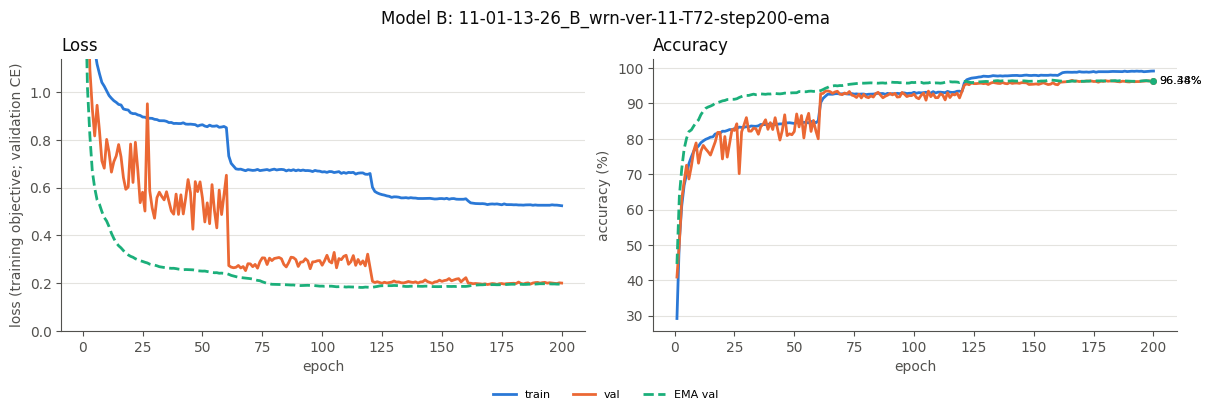

Saved /content/drive/MyDrive/DL_Project1/result/plots/11-01-13-26_B_wrn-ver-11-T72-step200-ema/11-01-13-26_B_wrn-ver-11-T72-step200-ema_curves.png


In [31]:
# Categorical colours in fixed order (one per run, or one per metric for a single run).
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"


def load_log(run_dir):
    df = pd.read_csv(artifact_path(paths_for_run(run_dir), "logs", "log", ".csv"))
    return df.apply(pd.to_numeric, errors="coerce")


def _style(ax, ylabel):
    ax.set_xlabel("epoch", color=INK_MUTED)
    ax.set_ylabel(ylabel, color=INK_MUTED)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(INK_MUTED)
    ax.tick_params(colors=INK_MUTED)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))


def _end_label(ax, df, col, color):
    s = df[["epoch", col]].dropna()
    if len(s):
        x, y = s.iloc[-1]
        ax.plot([x], [y], "o", color=color, markersize=4)
        ax.annotate(f"{y:.2f}%", (x, y), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8, color=INK)


def plot_runs(run_dirs, labels=None, out=None, title=None):
    """Two panels (loss, accuracy). One run: colour = metric. Several runs: colour = run,
    line style = metric (val solid, EMA val dashed, train dotted)."""
    run_dirs = [Path(r) for r in run_dirs]
    if len(run_dirs) > len(SERIES):
        raise ValueError(f"at most {len(SERIES)} runs per figure; split them into several figures")
    labels = labels or [r.name for r in run_dirs]
    single = len(run_dirs) == 1
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    losses = []

    for i, (run, name) in enumerate(zip(run_dirs, labels)):
        df = load_log(run)
        losses += [df[c].dropna().to_numpy() for c in ("train_loss", "val_loss", "ema_val_loss")]
        has_ema = df["ema_val_acc"].notna().any()
        if single:
            c_train, c_val, c_ema = SERIES[0], SERIES[1], SERIES[2]
            ls_train, prefix = "-", ""
        else:
            c_train = c_val = c_ema = SERIES[i]
            ls_train, prefix = ":", f"{name} "
        lw = dict(linewidth=2)
        train_label = "train weighted" if "mixup_batches" in df.columns else "train"
        ax_loss.plot(df["epoch"], df["train_loss"], ls_train, color=c_train, label=f"{prefix}{train_label}", **lw)
        ax_acc.plot(df["epoch"], df["train_acc"], ls_train, color=c_train, label=f"{prefix}{train_label}", **lw)
        if df["val_acc"].notna().any():
            ax_loss.plot(df["epoch"], df["val_loss"], "-", color=c_val, label=f"{prefix}val", **lw)
            ax_acc.plot(df["epoch"], df["val_acc"], "-", color=c_val, label=f"{prefix}val", **lw)
            _end_label(ax_acc, df, "val_acc", c_val)
        if has_ema:
            ax_loss.plot(df["epoch"], df["ema_val_loss"], "--", color=c_ema, label=f"{prefix}EMA val", **lw)
            ax_acc.plot(df["epoch"], df["ema_val_acc"], "--", color=c_ema, label=f"{prefix}EMA val", **lw)
            if single:
                _end_label(ax_acc, df, "ema_val_acc", c_ema)

    _style(ax_loss, "loss (training objective; validation CE)")
    _style(ax_acc, "accuracy (%)")
    ax_loss.set_title("Loss", color=INK, loc="left")
    ax_acc.set_title("Accuracy", color=INK, loc="left")
    loss_values = np.concatenate(losses)
    if len(loss_values) > 5:  # keep a few huge early-epoch losses from flattening the curves
        ax_loss.set_ylim(0, min(loss_values.max(), 1.2 * np.percentile(loss_values, 95)) * 1.05)
    handles, names = ax_acc.get_legend_handles_labels()
    fig.legend(handles, names, loc="outside lower center", ncol=3 if not single else len(names),
               frameon=False, fontsize=8)
    if title:
        fig.suptitle(title, color=INK)
    if out is not None:
        fig.savefig(out, dpi=150)
    return fig


fig = plot_runs([RUN_DIR], out=artifact_path(paths_for_run(RUN_DIR), "plots", "curves", ".png"), title=f"Model {MODEL}: {RUN_DIR.name}")
plt.show()
print(f"Saved {artifact_path(paths_for_run(RUN_DIR), 'plots', 'curves', '.png')}")

## 7. Prediction and submission

The checkpoint's dataset and architecture identities are checked before evaluation. For a validation run,
`WEIGHTS="auto"` selects raw or EMA weights using the requested inference mode: plain accuracy when `TTA=False`,
flip-TTA accuracy when `TTA=True`. This choice is among weights at the selected checkpoint; training selects
the best epoch using non-TTA validation. Full-data refits require explicit weights and use the completed `<RUN_ID>_last-ckpt.pt`.

Timestamped validation reports contain all four raw/EMA × plain/flip comparisons, per-class recall,
confusion matrices and per-example probabilities. Selected-model error plots are saved in `plots`.
Test predictions, format checks, checkpoint hashes and submission CSVs go in `evaluations/test`.
The CSV follows the sample's exact ID order; hidden-test accuracy remains unknown until Kaggle returns it.


In [32]:
def resolve_checkpoint(run_dir, which="best"):
    run_dir = Path(run_dir)
    last = checkpoint_path(run_dir, "last")
    if last.exists() and load_checkpoint(last)["args"]["val_size"] == 0:
        return last  # A full-data run always uses its agreed final epoch.
    path = checkpoint_path(run_dir, which)
    if not path.exists():
        raise FileNotFoundError(f"Requested checkpoint missing: {path}; resume the run to repair/recover it")
    return path


def choose_weights(ckpt, requested, tta=False, val_report=None):
    if requested not in ("auto", "model", "ema"):
        raise ValueError("weights must be auto, model or ema")
    if requested != "auto":
        if requested == "ema" and ckpt["ema"] is None:
            raise ValueError("Checkpoint has no EMA weights")
        return requested
    if not len(ckpt["val_idx"]):
        raise ValueError("No validation split: explicitly use the weights selected in earlier validation experiments")
    if not val_report:
        raise ValueError("Automatic selection requires a fresh validation report")
    metric = "flip_tta" if tta else "no_tta"
    # Ties favor raw weights, consistently with training's best-checkpoint convention.
    return max(val_report, key=lambda name: (val_report[name][metric], name == "model"))


def load_model(ckpt, weights, device):
    options = saved_architecture(ckpt["args"])
    model, n_params = build_model(architecture=options)
    if "architecture" in ckpt and ckpt["architecture"] != architecture_details(options):
        raise ValueError("Checkpoint resolved architecture differs from its saved options")
    if "n_params" in ckpt and ckpt["n_params"] != n_params:
        raise ValueError("Checkpoint parameter count differs from its saved architecture")
    if ckpt.get("model_fingerprint") != model_fingerprint(model) or ckpt["args"]["model"] != MODEL:
        raise ValueError("Checkpoint architecture differs from this notebook")
    model.load_state_dict(ckpt["ema"]["module"] if weights == "ema" else ckpt["model"])
    return model.to(device).eval(), n_params


def validate_submission(path, sample_path):
    sub, sample = pd.read_csv(path), pd.read_csv(sample_path)
    if list(sub.columns) != ["id", "label"] or len(sub) != len(sample):
        raise ValueError("Submission columns or row count differ from the sample")
    if not sub["id"].is_unique or not np.array_equal(sub["id"], sample["id"]):
        raise ValueError("Submission IDs are duplicated or differ from sample order")
    if not pd.api.types.is_integer_dtype(sub["label"]) or not sub["label"].between(0,9).all():
        raise ValueError("Submission labels must be integers in 0..9")
    return len(sub)


def classification_metrics(probs, labels):
    labels = np.asarray(labels)
    probs = np.asarray(probs)
    pred = probs.argmax(1)
    cm = np.bincount(labels * NUM_CLASSES + pred, minlength=NUM_CLASSES**2).reshape(NUM_CLASSES, NUM_CLASSES)
    support = cm.sum(1)
    recall = np.divide(cm.diagonal(), support, out=np.zeros(NUM_CLASSES, dtype=float), where=support > 0)
    return {"accuracy_pct": float((pred == labels).mean()*100), "correct": int((pred == labels).sum()),
            "n": len(labels), "cross_entropy": float(-np.log(probs[np.arange(len(labels)), labels].clip(1e-12)).mean()),
            "per_class_recall": {name: float(value) if count else None
                                 for name, value, count in zip(CLASSES, recall, support)},
            "confusion_matrix": cm.tolist()}


def val_accuracy(ckpt, data_dir, cache_dir, device, batch_size=1000, save_prefix=None):
    fingerprint = verify_cache(ensure_cache(data_dir, cache_dir))["fingerprint"]
    validate_checkpoint(ckpt, fingerprint)
    val_idx = ckpt["val_idx"].numpy()
    if not len(val_idx):
        return {}
    images, labels, ids = load_train(data_dir, cache_dir)
    vx, vy = images[val_idx], labels[val_idx]
    mean, std = ckpt["norm"]["mean"], ckpt["norm"]["std"]
    report, arrays = {}, {"ids": ids[val_idx], "indices": val_idx, "labels": vy}
    for weights in (["model", "ema"] if ckpt["ema"] is not None else ["model"]):
        model = load_model(ckpt, weights, device)[0]
        plain = F.softmax(predict_logits(model, vx, mean, std, device, batch_size), 1).numpy()
        flipped = F.softmax(predict_logits(model, vx, mean, std, device, batch_size, flip=True), 1).numpy()
        report[weights] = {"details": {}}
        for name, probs in (("no_tta", plain), ("flip_tta", 0.5*(plain+flipped))):
            metrics = classification_metrics(probs, vy)
            report[weights][name] = metrics["accuracy_pct"]
            report[weights]["details"][name] = metrics
            arrays[f"{weights}_{name}_probabilities"] = probs
            arrays[f"{weights}_{name}_predictions"] = probs.argmax(1)
    if save_prefix is not None:
        save_prefix = Path(save_prefix)
        with save_prefix.with_suffix(".npz").open("wb") as f:
            np.savez_compressed(f, **arrays)
        write_json_atomic({"epoch": ckpt["epoch"], "cache_fingerprint": fingerprint,
                           "normalization": ckpt["norm"], "metrics": report}, save_prefix.with_suffix(".json"))
    return report


def plot_validation_diagnostics(ckpt, weights, tta, report, arrays_path, data_dir, cache_dir, out_prefix):
    mode = "flip_tta" if tta else "no_tta"
    cm = np.array(report[weights]["details"][mode]["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(8,7), layout="constrained")
    ax.imshow(cm, cmap="Blues")
    ax.set(xticks=range(10), yticks=range(10), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel="Predicted label", ylabel="True label", title=f"Validation confusion matrix: {weights}, {mode}")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, str(cm[i,j]), ha="center", va="center", fontsize=8,
                    color="white" if cm[i,j] > cm.max()/2 else "black")
    fig.savefig(str(out_prefix)+"-confusion.png", dpi=150)
    plt.close(fig)
    with np.load(arrays_path, allow_pickle=False) as arrays:
        labels = arrays["labels"]
        predictions = arrays[f"{weights}_{mode}_predictions"]
        indices = arrays["indices"]
        wrong = np.flatnonzero(predictions != labels)[:12]
        if len(wrong):
            images = load_train(data_dir, cache_dir)[0]
            fig, axes = plt.subplots(3,4,figsize=(10,8),layout="constrained")
            for ax in axes.flat:
                ax.axis("off")
            for ax, pos in zip(axes.flat, wrong):
                ax.imshow(images[indices[pos]])
                ax.set_title(f"true: {CLASSES[labels[pos]]}\npred: {CLASSES[predictions[pos]]}", fontsize=9)
            fig.savefig(str(out_prefix)+"-errors.png", dpi=150)
            plt.close(fig)


def predict_run(run_dir, which="best", weights="auto", tta=True, data_dir=None, cache_dir=None, device=None,
                batch_size=1000):
    device = device or get_device(DEVICE)
    fingerprint = verify_cache(ensure_cache(data_dir, cache_dir))["fingerprint"]
    artifacts = paths_for_run(run_dir)
    ckpt_path = resolve_checkpoint(run_dir, which)
    ckpt = load_checkpoint(ckpt_path)
    validate_checkpoint(ckpt, fingerprint, run_id=artifacts.run_id)
    if ckpt["args"]["val_size"] == 0 and (ckpt["epoch"] != ckpt["args"]["epochs"] or ckpt["args"]["train_subset"]):
        raise ValueError("Full-data submission requires a completed run without a training subset")
    checkpoint_role = "last" if ckpt["args"]["val_size"] == 0 else which
    val_prefix = artifact_path(artifacts, "validation", f"{checkpoint_role}-validation", "", event=True, unique=True)
    val_report = val_accuracy(ckpt, data_dir, cache_dir, device, batch_size, save_prefix=val_prefix)
    weights = choose_weights(ckpt, weights, tta, val_report)
    model, n_params = load_model(ckpt, weights, device)
    mean, std = ckpt["norm"]["mean"], ckpt["norm"]["std"]
    print(f"Checkpoint {ckpt_path.name}, epoch {ckpt['epoch']}; weights {weights}; flip TTA {tta}; params {n_params:,}")
    for name, metrics in val_report.items():
        print(f"Validation {name}: plain {metrics['no_tta']:.2f}%, flip {metrics['flip_tta']:.2f}%")
    if val_report:
        plot_validation_diagnostics(ckpt, weights, tta, val_report, val_prefix.with_suffix(".npz"),
                                    data_dir, cache_dir, artifact_path(artifacts, "plots", checkpoint_role, "", event=True, unique=True))
    test_images, test_ids = load_test(data_dir, cache_dir)
    probs = predict_probs(model, test_images, mean, std, device, batch_size, tta=tta).numpy()
    sample_path = Path(cache_dir) / "sample_submission.csv"
    sample = pd.read_csv(sample_path)
    row_of = {int(value): i for i, value in enumerate(test_ids)}
    if len(row_of) != len(test_ids) or set(sample["id"]) != set(row_of):
        raise ValueError("Test IDs differ from sample or contain duplicates")
    order = np.array([row_of[int(value)] for value in sample["id"]])
    ordered = probs[order]
    out = artifact_path(artifacts, "test", "submission", ".csv", event=True, unique=True)
    pd.DataFrame({"id": sample["id"], "label": ordered.argmax(1).astype(np.int64)}).to_csv(out,index=False)
    n = validate_submission(out, sample_path)
    np.savez_compressed(out.with_name(out.stem.replace("_submission", "_probabilities") + ".npz"), ids=sample["id"].to_numpy(), probabilities=ordered)
    if detect_env() == "kaggle":
        shutil.copyfile(out, work_dir() / "submission.csv")
    report = {"checkpoint": str(ckpt_path), "checkpoint_sha256": sha256_file(ckpt_path),
              "epoch": ckpt["epoch"], "epochs": ckpt["args"]["epochs"], "model": MODEL, "n_params": n_params,
              "architecture": architecture_details(saved_architecture(ckpt["args"])),
              "model_description": model._project_description,
              "n_train": ckpt["n_train"], "n_val": len(ckpt["val_idx"]), "weights": weights, "tta": tta,
              "val": val_report, "submission": str(out), "rows": n, "format_check": "passed",
              "cache_fingerprint": fingerprint, "validation_artifact_prefix": str(val_prefix) if val_report else None,
              "kaggle_public_accuracy": None, "kaggle_private_accuracy": None}
    report["lr_schedule"] = ckpt.get("lr_schedule", {"kind": "cosine", "legacy": True})
    write_json_atomic(report, out.with_name(out.stem.replace("_submission", "_prediction-report") + ".json"))
    print(f"Submission saved: {out}. Hidden-test accuracy is not available locally.")
    return report


def export_run(run_dir, include_checkpoints=False):
    artifacts = paths_for_run(run_dir)
    records = []
    for name, folder in vars(artifacts).items():
        if name in ("root", "run_id", "exports", "manifests"):
            continue
        for path in sorted(folder.glob("*")):
            if path.is_file() and not path.name.endswith(".tmp"):
                records.append({"path": str(path.relative_to(artifacts.root)), "bytes": path.stat().st_size,
                                "sha256": sha256_file(path), "included_in_bundle": name != "checkpoints" or include_checkpoints})
    manifest = artifact_path(artifacts, "manifests", "manifest", ".json", event=True, unique=True)
    write_json_atomic({"run_id": artifacts.run_id, "files": records}, manifest)
    bundle = artifact_path(artifacts, "exports", "review-bundle", ".zip", event=True, unique=True)
    with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
        for record in records:
            if record["included_in_bundle"]:
                z.write(artifacts.root / record["path"], record["path"])
        z.write(manifest, str(manifest.relative_to(artifacts.root)))
    print(f"Review bundle: {bundle}")
    print(f"Keep full checkpoints separately in {artifacts.checkpoints}")
    return bundle


In [33]:
SUBMISSION = predict_run(RUN_DIR, CHECKPOINT, WEIGHTS, TTA, PATHS.data_dir, CACHE, DEV, EVAL_BATCH_SIZE)

# Compare the final and selected best epochs without confusing their identities.
VAL_RESULTS = {}
for key, name in (("final", "last-ckpt.pt"), ("best", "best-ckpt.pt")):
    path = checkpoint_path(RUN_DIR, key if key == "best" else "last")
    if not path.exists():
        continue
    ck = load_checkpoint(path)
    if ck["epoch"] == SUBMISSION["epoch"]:
        acc = SUBMISSION["val"]
    else:
        prefix = artifact_path(paths_for_run(RUN_DIR), "validation", f"{key}-validation", "", event=True, unique=True)
        acc = val_accuracy(ck, PATHS.data_dir, CACHE, DEV, EVAL_BATCH_SIZE, save_prefix=prefix)
    if acc:
        weights = choose_weights(ck, WEIGHTS, TTA, acc)
        VAL_RESULTS[key] = {"epoch": ck["epoch"], "weights": weights,
                            "no_tta": acc[weights]["no_tta"], "flip_tta": acc[weights]["flip_tta"]}
write_json_atomic(VAL_RESULTS, artifact_path(paths_for_run(RUN_DIR), "validation", "epoch-comparison", ".json", event=True, unique=True))


Checkpoint 11-01-13-26_B_wrn-ver-11-T72-step200-ema_best-ckpt.pt, epoch 157; weights ema; flip TTA True; params 4,298,970
Validation model: plain 95.44%, flip 95.98%
Validation ema: plain 96.64%, flip 96.62%
Submission saved: /content/drive/MyDrive/DL_Project1/result/evaluations/test/11-01-13-26_B_wrn-ver-11-T72-step200-ema/11-01-13-44_B_wrn-ver-11-T72-step200-ema_submission.csv. Hidden-test accuracy is not available locally.


## 8. Final results and review bundle

The last cell creates a compact ZIP with configuration, logs, evaluations, plots and a checksum manifest.
Full checkpoints stay separately on Drive and are excluded from this review bundle by default. Download the
bundle for each experiment after training. These bundles and actual Kaggle scores will support the next review
and the later `Archive/improvement.md`; no model refinements are inferred from unrun experiments.


In [34]:
artifacts = paths_for_run(RUN_DIR)
results = json.loads((artifact_path(artifacts, "logs", "report", ".json")).read_text())
print(f"FINAL RESULTS | scheme {MODEL}: {results.get('model_description', MODEL_DESCRIPTION)}")
print(f"Run ID: {artifacts.run_id}")
print(f"Parameters: {results['n_params']:,} / {PARAM_BUDGET:,}")
print(f"Training images: {results['n_train']:,}; validation images: {results['n_val']:,}")
print(f"Epochs: {results['epochs']}; compute time: {results['compute_time_min']:.2f} min; "
      f"wall time: {results['wall_time_s']/60:.2f} min; peak CUDA allocation: {results['peak_vram_mib']:.0f} MiB")
for key, value in VAL_RESULTS.items():
    print(f"{key}: epoch {value['epoch']}, {value['weights']}; plain {value['no_tta']:.2f}%, flip {value['flip_tta']:.2f}%")
if not VAL_RESULTS:
    print("No validation score for this full-data refit; use the earlier validation runs for model selection.")
print(f"Submission: {SUBMISSION['submission']}")
print(f"Format check: {SUBMISSION['format_check']}; rows: {SUBMISSION['rows']}")
print("Hidden-test accuracy: record the actual score returned by Kaggle separately.")
REVIEW_BUNDLE = export_run(RUN_DIR, include_checkpoints=False)


FINAL RESULTS | scheme B: WRN-22-4 (pre-activation, widths 16/64/128/256)
Run ID: 11-01-13-26_B_wrn-ver-11-T72-step200-ema
Parameters: 4,298,970 / 5,000,000
Training images: 45,000; validation images: 5,000
Epochs: 200; compute time: 16.70 min; wall time: 17.15 min; peak CUDA allocation: 3990 MiB
final: epoch 200, ema; plain 96.38%, flip 96.76%
best: epoch 157, ema; plain 96.64%, flip 96.62%
Submission: /content/drive/MyDrive/DL_Project1/result/evaluations/test/11-01-13-26_B_wrn-ver-11-T72-step200-ema/11-01-13-44_B_wrn-ver-11-T72-step200-ema_submission.csv
Format check: passed; rows: 2000
Hidden-test accuracy: record the actual score returned by Kaggle separately.
Review bundle: /content/drive/MyDrive/DL_Project1/result/exports/11-01-13-26_B_wrn-ver-11-T72-step200-ema/11-01-13-44_B_wrn-ver-11-T72-step200-ema_review-bundle.zip
Keep full checkpoints separately in /content/drive/MyDrive/DL_Project1/result/checkpoints/11-01-13-26_B_wrn-ver-11-T72-step200-ema
